# 02 — PSF characterisation per plane with uiPSF  (**Extension — not in the paper**)

**Purpose.** Measure the PSF of each of the 8 planes from the fluorescent-bead z-stack: learned pupil **magnitude** (how much
of the aperture carries light, effective NA) and **phase** (Zernike aberrations in nm), the learned **blur**, the fit quality,
and a width budget (ideal → + magnitude → + phase → + blur).

**SI references.** None for the method: the paper has no measured PSF. SI §6.3 (Figs. S12–S15) is a Zemax *design* analysis
(diffraction limited, Strehl > 0.95); SI §6.2 gives the prism path lengths that make the planes differ. The beads of SI §8.3 are
used in the paper only for co-registration, transmission and plane spacing (notebook 01).

**Inputs.** The bead z-stack (stage scan) and `<stem>_01_registration/calibration.json` from notebook 01 (panel windows,
orientations, Δz per plane, pixel, affine per plane). uiPSF (ries-lab, Liu et al., *Nat. Methods* 2024) installed in its own
environment, whose python is `uipsf_python` in `~/.mpqpi.yaml`.

**Outputs** (`<stem>_02_psf/`). `stacks/P*.tif` + `export.json` (uiPSF input), `fits/P*_zernike_vector_single.h5` (+ spec, log),
figures `N_*.png`, `psf_summary.json`.

**Extensions used** (everything here): uiPSF vectorial PSF fit per plane; effective NA from the learned pupil magnitude;
per-plane pixel from the calibration affine; numpy re-implementation of uiPSF's forward model for the width budget; plane-to-plane
split of the aberrations (common / depth trend / camera / rest). Optional and off by default: sample-motion correction at export.

Nothing in this notebook feeds notebooks 03–04.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, PowerNorm, TwoSlopeNorm
import tifffile

from mpqpi import io, psf_uipsf as pu
from mpqpi.config import Instrument, data_path, output_dir, local
from mpqpi.params import REG
from mpqpi.provenance import write_json

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
REG.clear()
inst = Instrument()

## 1. Parameters
Every value that changes the fit or its interpretation is declared here. `N_SAMPLE` is uiPSF's medium index (`RI.med`) **and**
the index used in every interpretation below (there is no separate "guess"): set it to the bead medium of *this* sample.

In [2]:
DATA = REG.declare("data_file", str(data_path("/Users/quentingresil/Library/CloudStorage/OneDrive-epfl.ch/POSTDOC/data/260928_registration/20260928_134359_GPSBeads_Stock_1-10_Agarpse_2_488nm_zstack.dat")),
                   "user", "bead z-stack (stage scan) of this session")
DATA = Path(DATA)
CALIB = Path(REG.declare("calibration_file", str(DATA.parent / f"{DATA.stem}_01_registration" / "calibration.json"), "user",
                         "notebook 01 output (DESIGN.md contract)"))
PLANES = REG.declare("planes_to_fit", ["P1", "P2", "P3", "P4", "P5", "P6", "P7", "P8"], "user",
                     "planes fitted (each fit ≈ 10–20 min on CPU; fitted planes are skipped)")
TAG = REG.declare("fit_tag", "", "user", "suffix of the result files; change it to keep fits made with other settings")
N_SAMPLE = REG.declare("n_sample", 1.33, "user", "bead medium index = uiPSF RI.med and every interpretation",
                       note="rewetted agarose ≈ water; a dried sample would be ≈ 1.0 — set to your sample")
N_COV = inst.value("detection.coverslip_n", "n_coverslip")          # enters only uiPSF's Fresnel factors

# uiPSF model options (heuristics: implementation choices, review them)
VAR_PHOTON = REG.declare("var_photon", False, "heuristic",
                         "one photon count per bead: the axial shape must be explained by pupil + blur, not by per-slice photons "
                         "(uiPSF's zernike default True lets them absorb axial misfit, audit D4); §5.2 checks the bleaching this assumes")
VAR_BLUR = REG.declare("var_blur", True, "heuristic", "learn a Gaussian blur σ (x, y) (uiPSF default); it also absorbs the pixel width")
BLUR0 = REG.declare("blur_sigma_init_px", 0.5, "heuristic", "initial blur σ (uiPSF default); initial value only", "px")
CONST_MAG = REG.declare("const_pupilmag", False, "heuristic", "learn the pupil magnitude (uiPSF default): basis of the NA-loss reading")
SYM_MAG = REG.declare("symmetric_mag", False, "heuristic", "magnitude not forced round-symmetric (uiPSF default); set True to test the "
                      "magnitude/blur trade-off")
WITH_APOID = REG.declare("with_apoid", True, "heuristic", "aplanatic apodization √cosθ_imm/cosθ_med in the model (uiPSF default); the "
                         "learned magnitude is relative to it")
WITH_IMM = REG.declare("with_IMM", False, "heuristic", "no depth-dependent index-mismatch term: stage-scan defocus = k_z,imm·z is exact; "
                       "the bead-depth aberration is absorbed into the learned phase/magnitude (uiPSF default)")
N_MAX = REG.declare("zernike_n_max", 8, "heuristic", "Zernike radial order for magnitude and phase (45 Noll terms, uiPSF default)")
PUPIL_PX = REG.declare("pupil_size_px", 64, "heuristic", "pupil grid (uiPSF default)", "px")
ITER = REG.declare("iterations", 200, "heuristic", "L-BFGS-B iterations per learning pass (uiPSF default); convergence not checked")
ROI_XY_UM = REG.declare("roi_xy_um", 2.3, "heuristic", "lateral ROI per bead (≈ 21 px at 111 nm); too small truncates the defocus rings "
                        "that carry the high-NA information", "µm")
ROI_Z_UM = REG.declare("roi_z_um", 4.2, "heuristic", "axial ROI per bead (21 slices at 200 nm)", "µm")
DET_SIG = REG.declare("detect_gauss_sigma_px", [2, 2, 2], "heuristic", "bead detection smoothing [z, y, x] (uiPSF default, 3D)", "px")
DET_KER = REG.declare("detect_max_kernel_px", [3, 3, 3], "heuristic", "bead detection local-max kernel [z, y, x] (uiPSF default)", "px")
PEAK_H = REG.declare("detect_peak_height", 0.2, "heuristic", "beads below this fraction of the brightest are rejected (uiPSF default)")
MAX_BEADS = REG.declare("max_beads", 60, "heuristic", "beads per plane (uiPSF default 40)")
BATCH = REG.declare("batch_size", 100, "heuristic", "≥ max_beads: all beads optimised together")
INC_Z_TOWARDS_OBJ = inst.value("stage.increasing_z_towards_objective", "increasing_z_moves_towards_objective")
MOTION_FILE = REG.declare("motion_correction_file", None, "user", "None = no motion correction (default); else .npy (T, 2) per-frame "
                          "sample shift (x, y) in oriented panel px, applied to all planes (extension)")
UIPSF_PYTHON = local().get("uipsf_python")
REDO_FITS = False                                      # True: refit even if a result with the same parameters exists

# analysis choices
AX_WIN = REG.declare("axial_window_px", 3, "heuristic", "on-axis profile = mean of the central 3 × 3 px", "px")
DISC_UM = REG.declare("raw_disc_radius_um", 1.7, "heuristic", "raw-signal disc around each bead (encloses the defocused rings)", "µm")
RING_UM = REG.declare("raw_ring_outer_um", 2.4, "heuristic", "local background ring disc..ring", "µm")
FADE_FLAG = REG.declare("photon_mismatch_flag", 1.5, "heuristic", "flag if fitted and raw signal change across the ROI differ by > ×1.5")
PROF_BINS = REG.declare("pupil_profile_bins", 20, "heuristic", "radial bins of the pupil-magnitude profile")
PROF_SECT = REG.declare("pupil_profile_sectors", 12, "heuristic", "angular sectors for the spread band")
INNER = REG.declare("pupil_norm_inner_frac", 0.5, "heuristic", "magnitude profile normalised to its mean inside r < 0.5·NA")
B_DZ = REG.declare("budget_dz_um", 0.05, "heuristic", "z grid of the budget forward model", "µm")
B_ZH = REG.declare("budget_z_half_um", 2.5, "heuristic", "budget z range ±", "µm")
B_OVS = REG.declare("budget_pixel_oversample", 3, "heuristic", "ideal detector = box pixel integration, 3 × 3 sub-samples per pixel")

calib = json.loads(CALIB.read_text())
OBJ = REG.declare("objective", calib["objective"], "user", "from calibration.json")
NA = inst.value(f"objectives.{OBJ}.na", "na")
N_IMM = inst.value(f"objectives.{OBJ}.n_immersion", "n_immersion")
LAM = inst.value("fluorescent_beads.emission_um", "emission_um")
BEAD_D = inst.value("fluorescent_beads.diameter_um", "bead_diameter_um")
GAIN = inst.value("cameras.gain_e_per_count", "gain_e_per_count")
OFFSET = inst.value("cameras.offset_counts", "offset_counts")
ptag = calib.get("provenance", {}).get("parameters", {}).get("pixel_um", {})
PX_REF = REG.declare("pixel_um_reference", calib["pixel_um"], ptag.get("tag", "derived"),
                     f"calibration.json ({ptag.get('source', 'notebook 01')})", "µm")
OUT = output_dir(DATA, "02_psf")
REG.banner()

HEURISTIC (28)  <- choices made in the code, review these
  var_photon                   =          false        one photon count per bead: the axial shape must be explained by pupil + blur, not by per-slice photons (uiPSF's zernike default True lets them absorb axial misfit, audit D4); §5.2 checks the bleaching this assumes
  var_blur                     =           true        learn a Gaussian blur σ (x, y) (uiPSF default); it also absorbs the pixel width
  blur_sigma_init_px           =            0.5 px     initial blur σ (uiPSF default); initial value only
  const_pupilmag               =          false        learn the pupil magnitude (uiPSF default): basis of the NA-loss reading
  symmetric_mag                =          false        magnitude not forced round-symmetric (uiPSF default); set True to test the magnitude/blur trade-off
  with_apoid                   =           true        aplanatic apodization √cosθ_imm/cosθ_med in the model (uiPSF default); the learned magnitude is

## 2. Inputs and consistency checks
* `n_sample` of this notebook vs the one recorded by notebook 01 (they may legitimately differ only if the sample changed).
* Stage direction: uiPSF's `stage_mov_dir` = "normal" means the stage moves *towards the objective* along the stack. Stacks are
  exported in increasing commanded z, so `stage_mov_dir` follows from `increasing_z_moves_towards_objective` — an instrument fact
  that the bead data cannot tell. Flipping it changes the sign of the even-m terms (astigmatism, spherical, quadrafoil); coma and
  trefoil and all between-plane comparisons are unaffected.

In [3]:
acq = io.load(DATA, inst)
STAGE_DIR = REG.declare("stage_mov_dir", pu.stage_mov_dir(INC_Z_TOWARDS_OBJ), "derived",
                        "increasing_z_moves_towards_objective, stacks exported in increasing commanded z")
print(f"{DATA.name}: {acq.n_frames} frames per stream, commanded step {acq.step_um():.3f} µm, z {acq.z_um['A'][0]:.2f} → {acq.z_um['A'][-1]:.2f} µm "
      f"({'increasing' if acq.step_um() > 0 else 'decreasing'} in acquisition order)")
print(f"uiPSF stage_mov_dir = {STAGE_DIR!r}  (assumes increasing z moves {'towards' if INC_Z_TOWARDS_OBJ else 'away from'} the objective — unverified)")
if abs(calib.get("n_sample", N_SAMPLE) - N_SAMPLE) > 1e-6:
    print(f"NOTE: n_sample here {N_SAMPLE} ≠ calibration.json {calib.get('n_sample')} — make sure this is intended")
if abs(calib.get("n_immersion", N_IMM) - N_IMM) > 1e-6:
    print(f"NOTE: n_immersion instrument {N_IMM} ≠ calibration.json {calib.get('n_immersion')}")
if N_SAMPLE < NA:
    print(f"n_sample {N_SAMPLE} < NA {NA}: light beyond NA = {N_SAMPLE} is evanescent in the sample (reaches the objective only for beads "
          f"within ~λ of the coverslip); a pupil dark beyond NA = n_sample is expected, not an objective defect")
plane_info = {p["plane"]: p for p in calib["planes"]}
print("planes:", ", ".join(f"{p['plane']}({p['stream']}, Δz {p.get('delta_z_um', float('nan')):+.2f})" for p in calib["planes"]))

20260928_134359_GPSBeads_Stock_1-10_Agarpse_2_488nm_zstack.dat: 60 frames per stream, commanded step 0.250 µm, z 0.00 → 14.75 µm (increasing in acquisition order)
uiPSF stage_mov_dir = 'normal'  (assumes increasing z moves towards the objective — unverified)
planes: P1(B, Δz +0.00), P2(A, Δz +0.70), P3(B, Δz +0.79), P4(A, Δz +1.53), P5(B, Δz +1.60), P6(A, Δz +2.33), P7(B, Δz +2.36), P8(A, Δz +3.13)


## 3. Export the oriented plane stacks
Each plane's panel is cut with its `window_raw`, flipped by its `orientation` (so all planes look like the reference),
offset-subtracted (DESIGN rule 5) and written as float32 (no rounding / clipping) with frames in increasing commanded z. No
resampling between planes; no motion correction unless `motion_correction_file` is set (extension, periodic Fourier shift).
Per-plane pixel = reference pixel / √|det A| of the plane's affine (the magnifications differ slightly between planes).

In [4]:
motion = np.load(MOTION_FILE) if MOTION_FILE else None
man = pu.export_planes(acq, calib, OUT / "stacks", OFFSET, planes=PLANES, motion_px=motion)
for m in man["planes"]:
    print(f"{m['plane']}: {m['shape']}  pixel {1e3 * m['pixel_um']:.1f} nm (scale {m['scale']:.4f}, rotation {m['rotation_deg']:+.2f}°), "
          f"step {1e3 * m['step_um']:.0f} nm")
EXP = {m["plane"]: m for m in man["planes"]}

P1: [60, 880, 392]  pixel 111.4 nm (scale 1.0003, rotation -0.03°), step 250 nm
P2: [60, 880, 392]  pixel 111.4 nm (scale 1.0005, rotation -0.14°), step 250 nm
P3: [60, 880, 392]  pixel 111.4 nm (scale 0.9999, rotation -0.04°), step 250 nm
P4: [60, 880, 392]  pixel 111.5 nm (scale 0.9998, rotation -0.12°), step 250 nm
P5: [60, 880, 392]  pixel 111.4 nm (scale 1.0000, rotation +0.00°), step 250 nm
P6: [60, 880, 392]  pixel 111.4 nm (scale 0.9999, rotation -0.08°), step 250 nm
P7: [60, 880, 392]  pixel 111.4 nm (scale 0.9999, rotation +0.00°), step 250 nm
P8: [60, 880, 392]  pixel 111.5 nm (scale 0.9997, rotation -0.09°), step 250 nm


## 4. uiPSF fits (one subprocess per plane)
The full parameter set is built explicitly (`pu.uipsf_params`) and written next to the result (`*_spec.json`); every other
setting is uiPSF's default (config_base + psftype/zernike + channeltype/1ch), recorded in the result file. The data are already
offset-subtracted, so uiPSF's `ccd_offset` is 0 and only the gain is applied. A plane already fitted with the same parameters is
skipped. Each fit takes ≈ 10–20 min on CPU.

In [5]:
UIPSF_VERSION = pu.uipsf_version(UIPSF_PYTHON) if UIPSF_PYTHON else None
REG.declare("uipsf_defaults", f"uiPSF {UIPSF_VERSION or '?'} config_base + zernike + 1ch", "heuristic",
            "all uiPSF settings not set here (loss weights, outlier thresholds, ...) stay at the uiPSF defaults")
H5 = {}
for pl in PLANES:
    m = EXP[pl]
    name = pl + (f"_{TAG}" if TAG else "")
    prm = pu.uipsf_params(stack_file=OUT / "stacks" / m["file"], savename=OUT / "fits" / name, pixel_um=m["pixel_um"],
                          step_um=m["step_um"], na=NA, n_immersion=N_IMM, n_sample=N_SAMPLE, n_coverslip=N_COV, emission_um=LAM,
                          bead_diameter_um=BEAD_D, gain_e_per_count=GAIN, offset_counts=0.0, roi_xy_um=ROI_XY_UM,
                          roi_z_um=ROI_Z_UM, detect_sigma_px=DET_SIG, detect_kernel_px=DET_KER, peak_height=PEAK_H,
                          max_beads=MAX_BEADS, batch_size=BATCH, var_photon=VAR_PHOTON, var_blur=VAR_BLUR, blur_sigma_px=BLUR0,
                          const_pupilmag=CONST_MAG, symmetric_mag=SYM_MAG, with_apoid=WITH_APOID, with_imm=WITH_IMM, n_max=N_MAX,
                          pupil_size=PUPIL_PX, iterations=ITER, stage_mov_dir=STAGE_DIR)
    if pl == PLANES[0]:
        print(f"uiPSF settings ({pl}): ROI {prm['roi']['roi_size']} [z, y, x] px, pixel {1e3 * m['pixel_um']:.1f} nm, NA {NA}, "
              f"λ {LAM} µm, RI imm/med/cov {N_IMM}/{N_SAMPLE}/{N_COV}, bead Ø {BEAD_D} µm, gain {GAIN}, stage_mov_dir {STAGE_DIR}")
    print(f"--- {pl}")
    try:
        H5[pl] = pu.run_plane(prm, UIPSF_PYTHON, overwrite=REDO_FITS)
    except RuntimeError as e:
        print(f"{pl}: {e}")
print("fitted:", list(H5))

uiPSF settings (P1): ROI [17, 21, 21] [z, y, x] px, pixel 111.4 nm, NA 1.2, λ 0.515 µm, RI imm/med/cov 1.33/1.33/1.52, bead Ø 0.175 µm, gain 0.46, stage_mov_dir normal
--- P1
  [   10 s] /Users/quentingresil/Library/CloudStorage/OneDrive-epfl.ch/POSTDOC/data/260928_registration/20260928_134359_GPSBeads_Stock_1-10_Agarpse_2_488nm_zstack
  [   10 s] (1, 60, 880, 392)
  [   10 s] rois shape channel : (16, 17, 21, 21)
  [   12 s] 3/6: learning: 0/250 [00:00s] ?it/s, current loss: 0.00000, total time: 0.00s
  [   43 s] 3/6: learning: 64/250 [00:31s]  2.26it/s, current loss: 0.61265, total time: 31.36s
  [   73 s] 3/6: learning: 119/250 [01:01s]  2.13it/s, current loss: 0.60880, total time: 61.76s
  [  104 s] 3/6: learning: 185/250 [01:32s]  2.27it/s, current loss: 0.60747, total time: 92.54s
  [  115 s] 4/6: calculating spline coefficients: 0/1 [00:00s] ?it/s total time: 103.64s
  [  115 s] 5/6: localization: 0/10 [00:00s] ?it/s total time: 103.64s
  [  115 s] 4/6: calculating spline coeffi

## 5. Per-plane report
For each plane: **5.1** fit montage (bead-averaged data, model, residual; data and model averaged identically), relative residual
vs the photon-noise floor; **5.2** per-slice photons vs raw signal; **5.3** pupil magnitude (relative to the ideal aplanatic pupil
with the same NA, n_imm and n_sample) and phase (Zernike, nm RMS); **5.4** lateral width through focus and axial profile (data,
model, ideal); **5.5** width budget.

*Effective NA* = NA of a uniformly filled pupil with the same light-weighted mean NA² as the learned one, weight = |M|², M relative
to the ideal aplanatic pupil; a perfect pupil gives exactly the nominal NA (tested). Widths are those of the bead *image* (bead
Ø and pixel included) for data, model and ideal alike. The axial axis is the stage displacement.

*Budget.* uiPSF's forward model is rebuilt in numpy (checked against uiPSF's own model, deviation printed) and evaluated with the
learned terms switched on one by one: ideal (M = 1, Φ = 0, box pixel integration) → + magnitude → + phase → + learned blur (which
*replaces* pixel integration, as in uiPSF). The terms do not add in quadrature exactly, so each term's share depends on the order:
the shares are given as the range over all 6 orders. The ideal uses the same n_sample, n_imm and bead as the fit, so it is the
ideal *for this sample model*, not a sample-independent one.

In [6]:
C_D, C_M, C_I = "#2a78d6", "#eb6834", "#52514e"
RES, REP = {}, {}


def fit_montage(pl, res, D, M, rb, floor, sec):
    nz, ny, nx = D.shape; kz0 = int(np.argmax(D.max((1, 2)))); peak = D[kz0].max()
    show = [k for k in range(kz0 - 8, kz0 + 9, 2) if 0 <= k < nz]
    dz, px = res["optics"]["dz_um"], res["optics"]["px_um"]
    rmax = 100 * np.abs(D - M).max() / peak
    fig, ax = plt.subplots(3, len(show) + 2, figsize=(1.6 * len(show) + 6, 5.4), layout="constrained")
    for j, k in enumerate(show):
        for i, img in enumerate((D[k], M[k], 100 * (D[k] - M[k]) / peak)):
            if i < 2:
                ax[i, j].imshow(np.clip(img, 0, None), cmap="magma", norm=PowerNorm(0.5, 0, peak))
            else:
                h = ax[i, j].imshow(img, cmap="RdBu_r", norm=TwoSlopeNorm(0, -rmax, rmax))
            ax[i, j].set_xticks([]); ax[i, j].set_yticks([])
        ax[0, j].set_title(f"{1e3 * (k - kz0) * dz:+.0f} nm", fontsize=8)
    for i, lab in enumerate(("data", "model", "data − model")):
        ax[i, 0].set_ylabel(lab)
    ext = [-nx / 2 * px, nx / 2 * px, nz / 2 * dz, -nz / 2 * dz]
    for jj, f in enumerate((lambda V: V[:, ny // 2, :], lambda V: V[:, :, nx // 2])):
        for i, V in enumerate((D, M, D - M)):
            a = ax[i, len(show) + jj]
            if i < 2:
                a.imshow(np.clip(f(V) / peak, 1e-3, 1), cmap="magma", norm=LogNorm(1e-3, 1), extent=ext, aspect="auto")
            else:
                a.imshow(100 * f(V) / peak, cmap="RdBu_r", norm=TwoSlopeNorm(0, -rmax, rmax), extent=ext, aspect="auto")
        ax[0, len(show) + jj].set_title("xz" if jj == 0 else "yz", fontsize=8); ax[2, len(show) + jj].set_xlabel("µm")
    fig.colorbar(h, ax=ax[2, :], shrink=0.8, label="% of peak")
    fig.suptitle(f"{pl}: mean of {len(rb)} beads — residual {np.median(rb):.3f} (photon noise floor {np.median(floor):.3f})")
    fig.savefig(OUT / f"{sec}_{pl}_1_fit.png"); plt.show()


def photon_check(pl, chk, sec):
    if chk is None:
        print("no bead fully inside the panel for the raw-signal check"); return None
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), layout="constrained")
    k = np.arange(chk["raw_norm"].shape[1])
    ax[0].fill_between(k, *np.percentile(chk["raw_norm"], [25, 75], 0), color=C_D, alpha=0.2, lw=0)
    ax[0].plot(k, np.median(chk["raw_norm"], 0), color=C_D, lw=2, label="raw signal (disc − ring) × gain")
    ax[0].plot(k, np.median(chk["fit_norm"], 0), "-o", ms=3, color=C_M, lw=1.5, label="uiPSF photons per slice")
    ax[0].set(xlabel="ROI slice", ylabel="signal / signal at bead focus", title="signal through the ROI (median of beads)"); ax[0].legend()
    ax[1].hist(chk["fit_photons"].mean(1) / chk["raw_photons"].mean(1), bins=15, color=C_M)
    ax[1].set(xlabel="uiPSF photons / raw photons (ROI mean)", ylabel="beads", title="absolute photon scale")
    fig.savefig(OUT / f"{sec}_{pl}_2_photons.png"); plt.show()
    flag = abs(np.log(chk["change_fit"] / chk["change_raw"])) > np.log(FADE_FLAG)
    print(f"across the ROI: uiPSF photons ×{chk['change_fit']:.2f}, raw signal ×{chk['change_raw']:.2f}; photons fit/raw at focus "
          f"{chk['ratio_fit_over_raw_at_focus']:.2f}" + ("  -> MISMATCH: " + ("photons compensate an axial misfit" if VAR_PHOTON else
          "the raw signal changes (bleaching?) while the model assumes constant photons") if flag else ""))
    return bool(flag)


def pupil_figure(pl, res, mag, ph, sec):
    o = res["optics"]; na = o["na"]
    nac, prof, lo, hi, mrel = pu.radial_profile(mag, na, PROF_BINS, PROF_SECT, INNER)
    naeff = pu.effective_na(mag, na)
    c, W, S = pu.phase_nm(res)
    r, _ = pu.pupil_grid(mag.shape[-1])
    phmap = np.where(r < 1, np.tensordot(res["zernike_coeff"][1, 4:], res["zernike_polynomial"][4:], 1) * 1e3 * o["lam_um"] / (2 * np.pi), np.nan)
    fig = plt.figure(figsize=(15, 7.5), layout="constrained"); gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 1.3])
    a = fig.add_subplot(gs[0, 0]); h = a.imshow(mrel, cmap="magma", vmin=0, vmax=1.2, origin="lower", extent=[-na, na, -na, na])
    if o["n_med"] < na:
        a.add_patch(plt.Circle((0, 0), o["n_med"], fill=False, ec="w", ls=":"))
    a.set(title="magnitude / ideal", xlabel="NA_x", ylabel="NA_y"); fig.colorbar(h, ax=a, shrink=0.8)
    a = fig.add_subplot(gs[0, 1]); vm = np.nanmax(np.abs(phmap))
    h = a.imshow(phmap, cmap="RdBu_r", norm=TwoSlopeNorm(0, -vm, vm), origin="lower", extent=[-na, na, -na, na])
    a.set(title=f"phase, Noll ≥ 5 ({W:.0f} nm RMS)", xlabel="NA_x"); fig.colorbar(h, ax=a, shrink=0.8, label="nm")
    a = fig.add_subplot(gs[0, 2])
    a.fill_between(nac, lo, hi, color=C_M, alpha=0.2, lw=0, label=f"spread over {PROF_SECT} sectors")
    a.plot(nac, prof, color=C_M, lw=2, label="learned (azimuthal mean)"); a.axhline(1, color=C_I, ls="--", lw=1, label="ideal")
    a.axvline(naeff, color=C_M, ls="-.", lw=1, label=f"NA_eff {naeff:.3f}")
    if o["n_med"] < na:
        a.axvline(o["n_med"], color="C3", ls=":", label=f"NA = n_sample {o['n_med']}")
    a.set(xlim=(0, na), ylim=(0, 1.3), xlabel="NA", ylabel=f"magnitude (1 = mean inside {INNER}·NA)", title="radial magnitude"); a.legend(fontsize=7)
    a = fig.add_subplot(gs[1, :]); js = np.arange(5, len(c) + 1)
    a.bar(js, c[js - 1], color=[C_M if abs(c[j - 1]) >= 1e3 * o["lam_um"] / 100 else "#c9c8c2" for j in js])
    for j in js:
        if j in pu.ZNAME and abs(c[j - 1]) >= 1e3 * o["lam_um"] / 100:
            a.annotate(pu.ZNAME[j], (j, c[j - 1]), fontsize=7, ha="center", va="bottom" if c[j - 1] > 0 else "top", rotation=90)
    a.axhline(0, color="k", lw=0.5)
    a.set(xlabel="Noll j (1–4 = position, not shown)", ylabel="nm RMS",
          title=f"Zernike phase (grey: |c| < λ/100); total {W:.0f} nm, Maréchal Strehl {S:.2f}; stage_mov_dir {o['stage_mov_dir']}")
    fig.suptitle(f"{pl}: learned pupil (n_imm {o['n_imm']}, n_sample {o['n_med']})")
    fig.savefig(OUT / f"{sec}_{pl}_3_pupil.png"); plt.show()
    return dict(na_eff=naeff, profile_na=nac.tolist(), profile=prof.tolist(), phase_nm=c.tolist(), W_nm=W, strehl_marechal=S)


def widths_figure(pl, res, wt, bud, zf, sec):
    px, dz = 1e3 * res["optics"]["px_um"], res["optics"]["dz_um"]
    nb, nz = wt["fwhm_data_px"].shape[:2]
    rel = (np.arange(nz)[None] - wt["focus_slice"][:, None]) * dz
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), layout="constrained")
    V0 = bud["volumes"][(0, 0, 0)]; k0 = bud["states"]["000"]["focus"]
    for i, lab in enumerate("xy"):
        for arr, col, name in ((wt["fwhm_data_px"], C_D, "data"), (wt["fwhm_model_px"], C_M, "model")):
            offs = np.unique(rel); offs = offs[np.abs(offs) <= 1.0 + 1e-9]          # Gaussian widths are meaningless far out
            med = [np.nanmedian(arr[..., i][rel == o]) if (rel == o).sum() > 2 else np.nan for o in offs]
            ax[i].plot(1e3 * offs, px * np.array(med), "-o", ms=3, color=col, label=name)
        sel = np.abs(zf - zf[k0]) <= 1.0
        ideal = [pu.gauss_fwhm(V0[k] / V0[k].max())[i] * px for k in np.where(sel)[0]]
        ax[i].plot(1e3 * (zf[sel] - zf[k0]), ideal, "--", color=C_I, label="ideal")
        ax[i].set(xlabel="defocus (nm)", ylabel=f"FWHM {lab} (nm)", ylim=(0, 1000), title=f"lateral FWHM {lab}"); ax[i].legend()
    bg = res["bg"][:, None]
    cd = pu.on_axis(res["data"] - bg[..., None, None], AX_WIN); cm = pu.on_axis(res["fit"] - bg[..., None, None], AX_WIN)
    for prof, col, name in ((cd, C_D, "data"), (cm, C_M, "model")):
        p = np.median(prof / prof.max(1, keepdims=True), 0); ax[2].plot(1e3 * (np.arange(nz) - np.argmax(p)) * dz, p, "-o", ms=3, color=col, label=name)
    a0 = pu.on_axis(V0, AX_WIN); ax[2].plot(1e3 * (zf - zf[np.argmax(a0)]), a0 / a0.max(), "--", color=C_I, label="ideal")
    ax[2].set(xlabel="stage z − focus (nm)", ylabel="on-axis signal", xlim=(-2000, 2000),
              title=f"axial: FWHM data {1e3 * np.nanmedian(wt['axial_data_um']):.0f}, model {1e3 * np.nanmedian(wt['axial_model_um']):.0f}, "
                    f"ideal {1e3 * bud['states']['000']['fwhm_z_um']:.0f} nm"); ax[2].legend()
    fig.suptitle(f"{pl}: widths through focus (image of the {2e3 * res['optics']['bead_radius_um']:.0f} nm bead)")
    fig.savefig(OUT / f"{sec}_{pl}_4_widths.png"); plt.show()


def budget_figure(pl, bud, wt, res, sec):
    s = bud["states"]; seq = bud["sequence"]; px = res["optics"]["px_um"]
    labels = ["ideal", "+ magnitude", "+ phase", "+ blur\n= model", "data"]
    lat = [1e3 * s[k]["fwhm_lat_um"] for k in seq] + [1e3 * px * np.nanmean(wt["focus_data_px"])]
    axl = [1e3 * s[k]["fwhm_z_um"] for k in seq] + [1e3 * np.nanmedian(wt["axial_data_um"])]
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.8), layout="constrained", gridspec_kw={"width_ratios": [1, 1, 0.9]})
    for a, vals, t in ((ax[0], lat, "lateral FWHM at focus (nm)"), (ax[1], axl, "axial FWHM (nm)")):
        a.bar(range(5), vals, color=[C_I, C_M, C_M, C_M, C_D])
        for j, v in enumerate(vals):
            a.annotate(f"{v:.0f}" + ("" if j in (0, 4) else f"\n({v - vals[j - 1]:+.0f})"), (j, v), ha="center", va="bottom", fontsize=8)
        a.set_xticks(range(5)); a.set_xticklabels(labels, fontsize=8); a.set(title=t, ylim=(0, 1.3 * np.nanmax(vals)))
    ax[2].axis("off")
    txt = "share of the excess width² (ideal → model),\nrange over the 6 orders of adding terms:\n\n"
    for n, d in bud["share_range"].items():
        txt += f"{n:10s} lateral {100 * d['lateral'][0]:+4.0f}…{100 * d['lateral'][1]:+4.0f} %\n{'':10s} axial   {100 * d['axial'][0]:+4.0f}…{100 * d['axial'][1]:+4.0f} %\n"
    ax[2].text(0, 1, txt, va="top", family="monospace", fontsize=8.5)
    fig.suptitle(f"{pl}: width budget (bars: magnitude → phase → blur order)")
    fig.savefig(OUT / f"{sec}_{pl}_5_budget.png"); plt.show()
    return dict(lateral_nm=dict(zip([l.replace("\n", " ") for l in labels], lat)), axial_nm=dict(zip([l.replace("\n", " ") for l in labels], axl)),
                share_range=bud["share_range"])

=================== P1


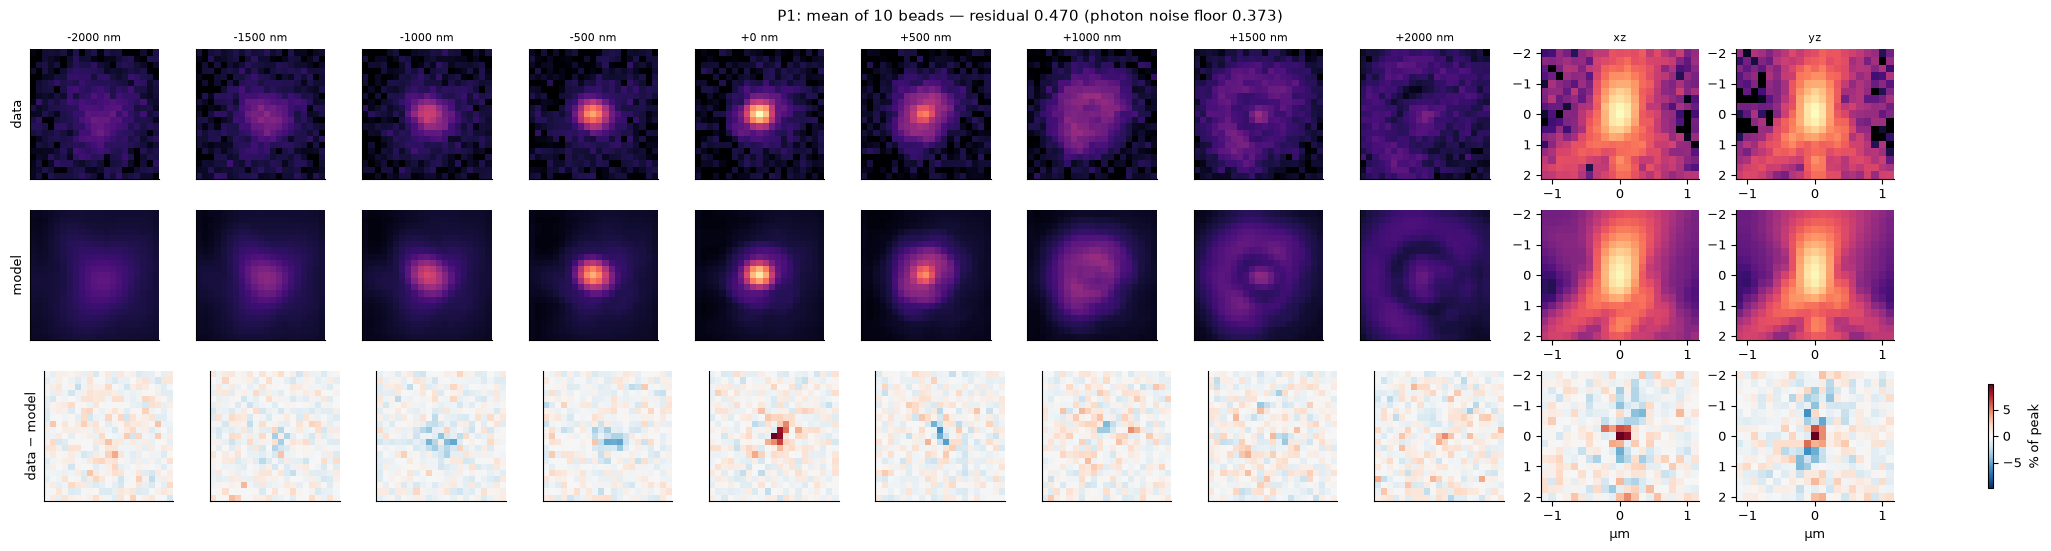

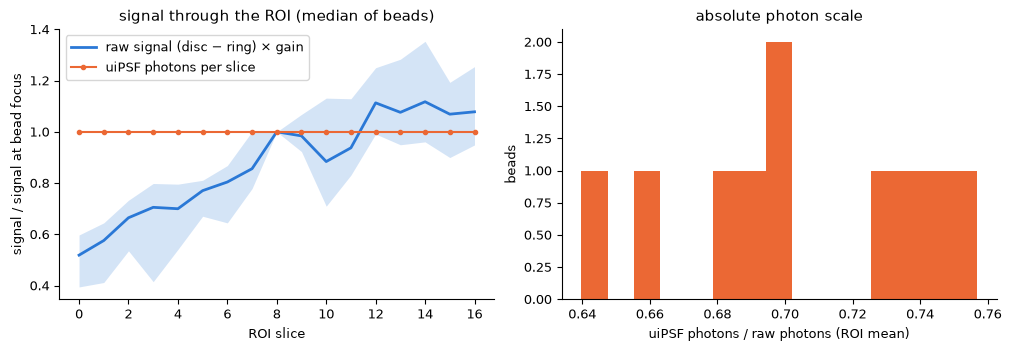

across the ROI: uiPSF photons ×1.00, raw signal ×1.94; photons fit/raw at focus 0.61  -> MISMATCH: the raw signal changes (bleaching?) while the model assumes constant photons


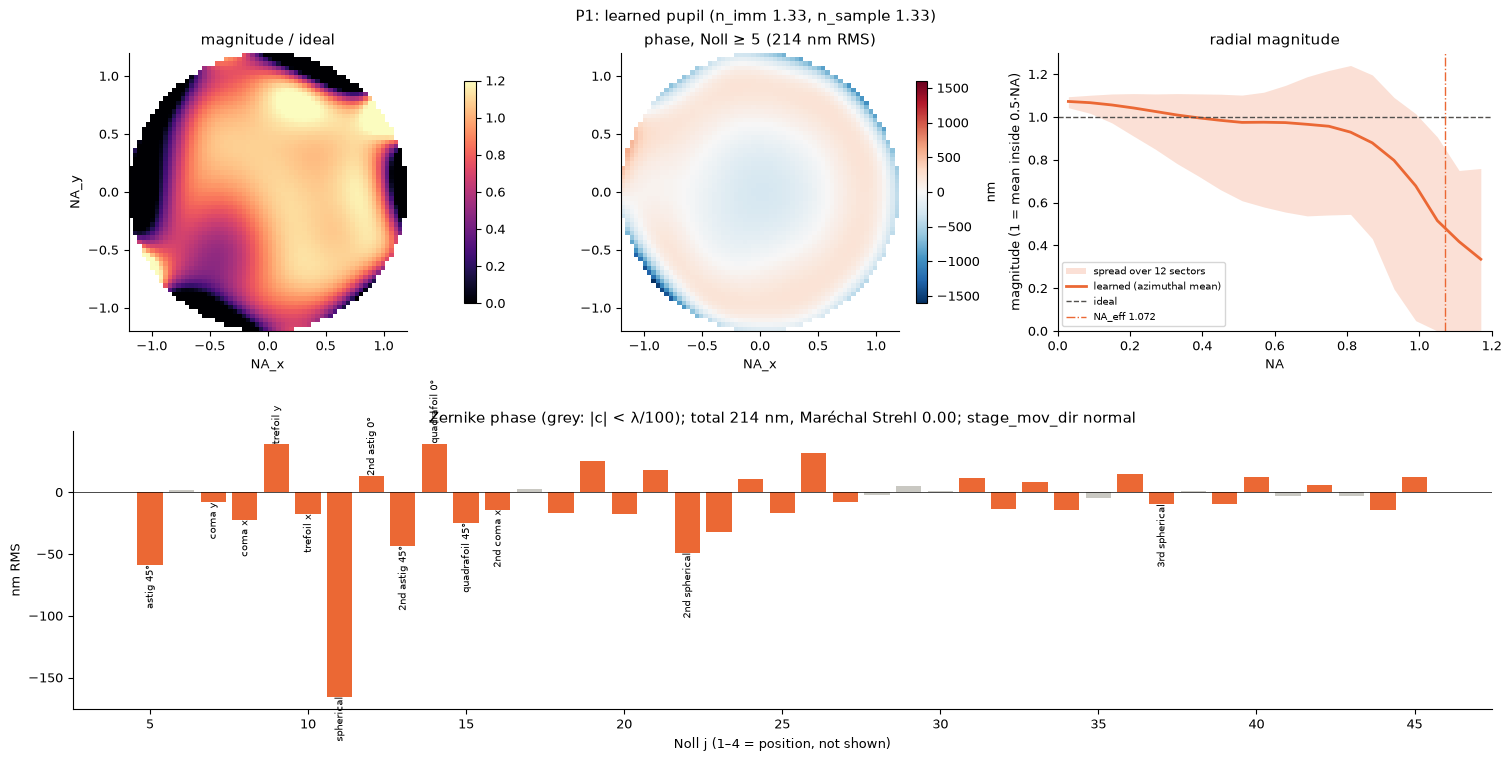

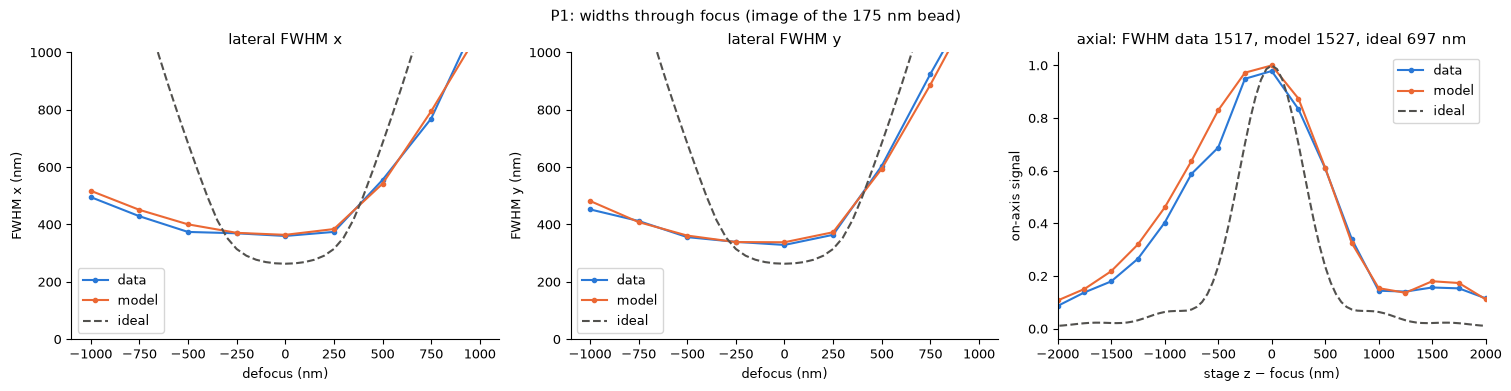

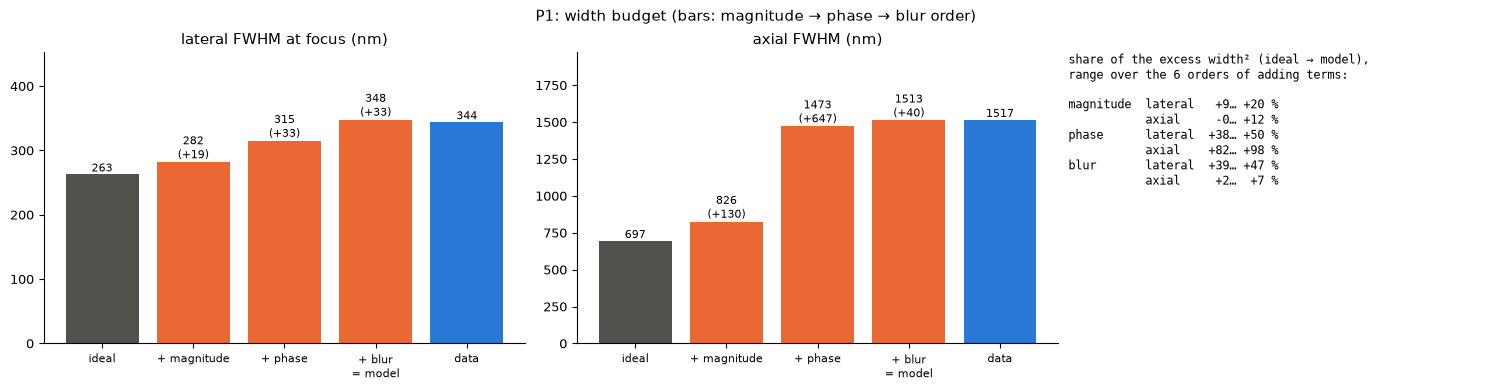

10 beads; residual 0.470 vs photon-noise floor 0.373; pupil rebuild dev 4.3e-06; forward-model port vs uiPSF 4.0e-07
NA_eff 1.072 (nominal 1.2); phase 213.6 nm RMS (Strehl 0.00); blur σ_y/σ_x 57/75 nm (pixel alone ≈ 32)
FWHM at focus x/y: data 360/329 nm, model 364/338 nm
=================== P2


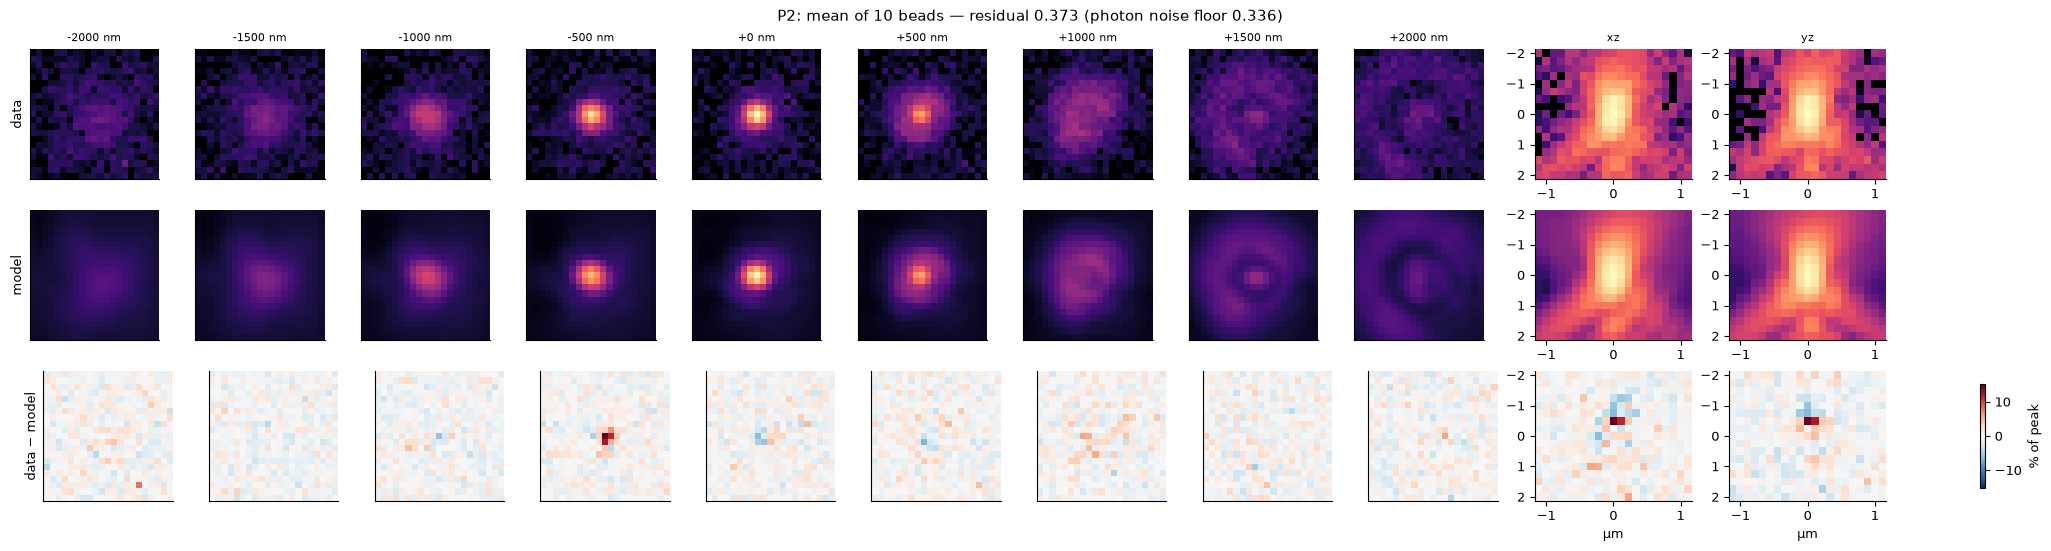

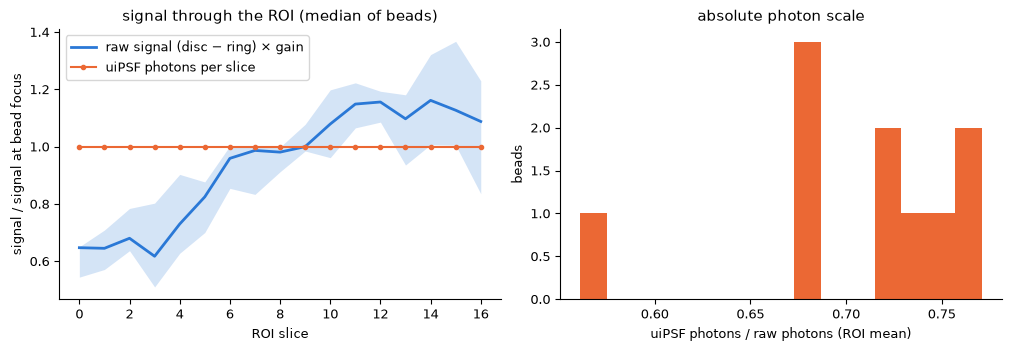

across the ROI: uiPSF photons ×1.00, raw signal ×1.85; photons fit/raw at focus 0.67  -> MISMATCH: the raw signal changes (bleaching?) while the model assumes constant photons


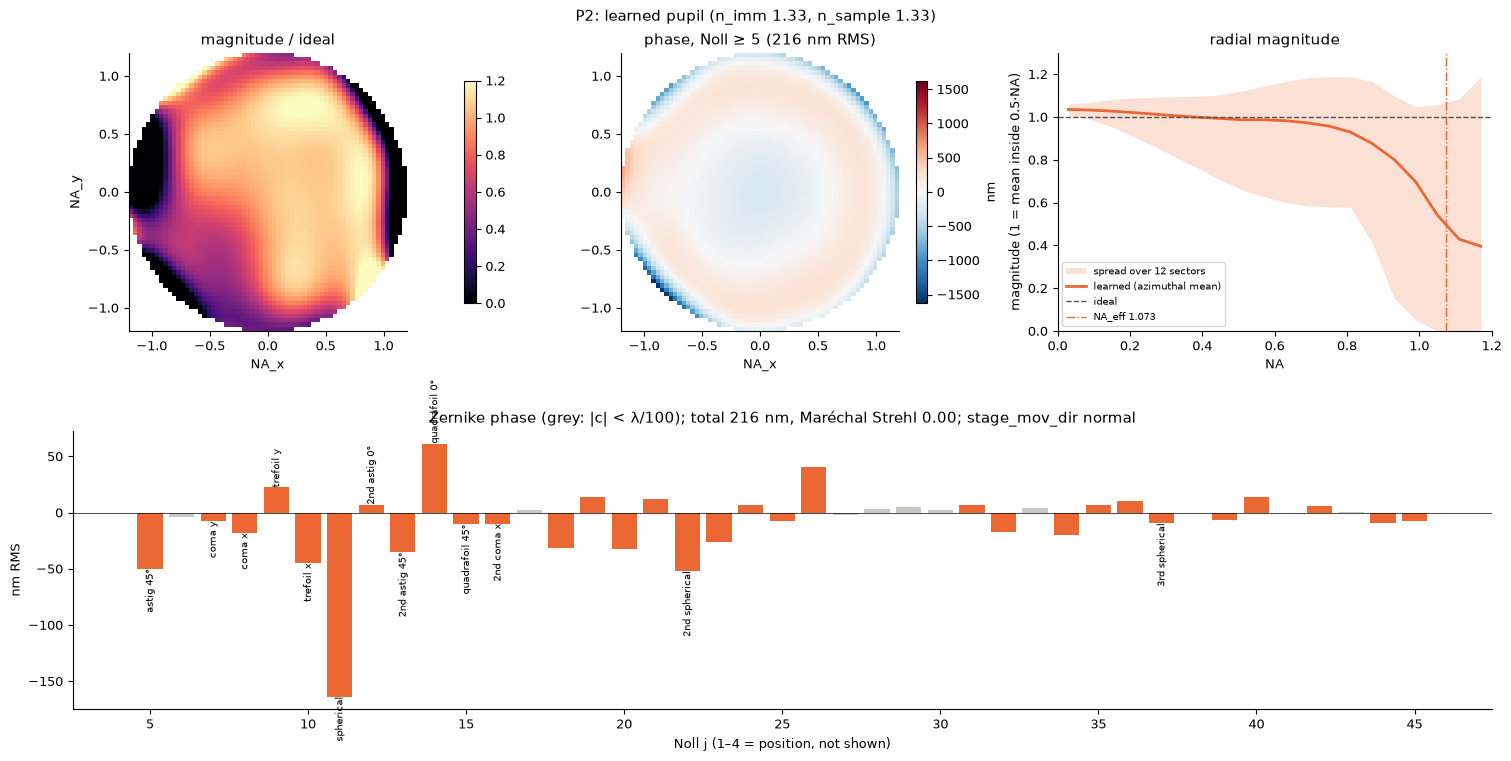

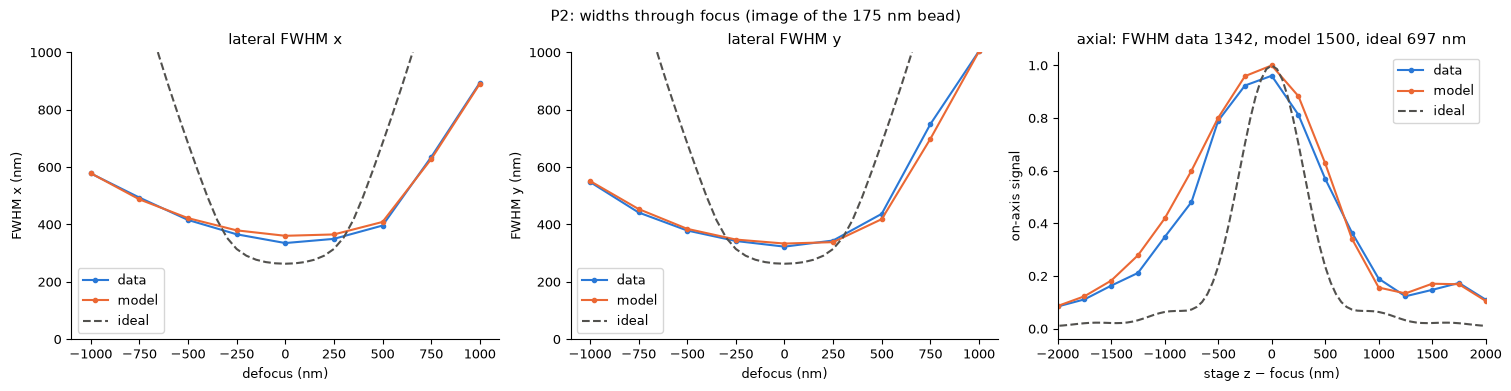

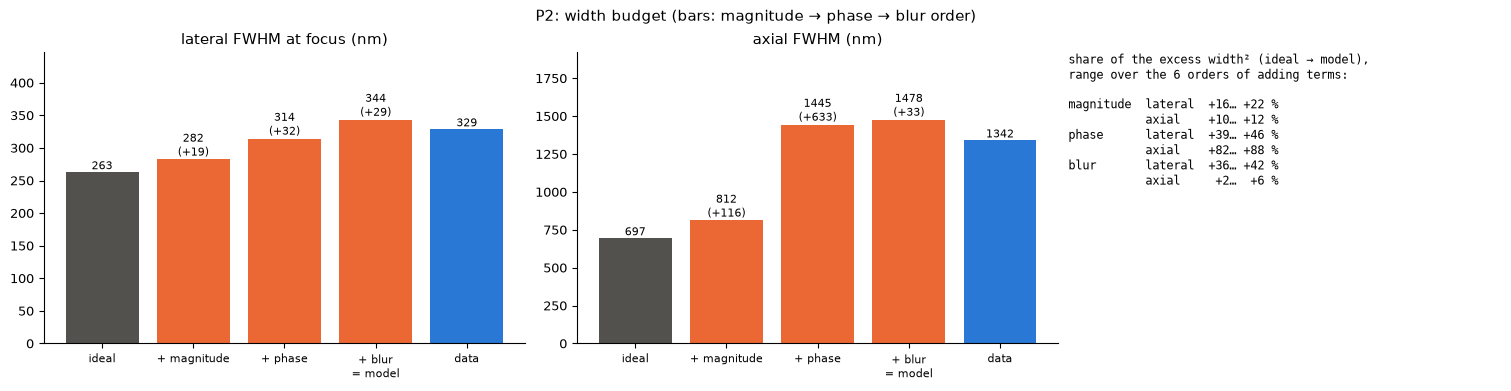

10 beads; residual 0.373 vs photon-noise floor 0.336; pupil rebuild dev 2.2e-06; forward-model port vs uiPSF 2.5e-07
NA_eff 1.073 (nominal 1.2); phase 215.6 nm RMS (Strehl 0.00); blur σ_y/σ_x 55/71 nm (pixel alone ≈ 32)
FWHM at focus x/y: data 335/323 nm, model 361/334 nm
=================== P3


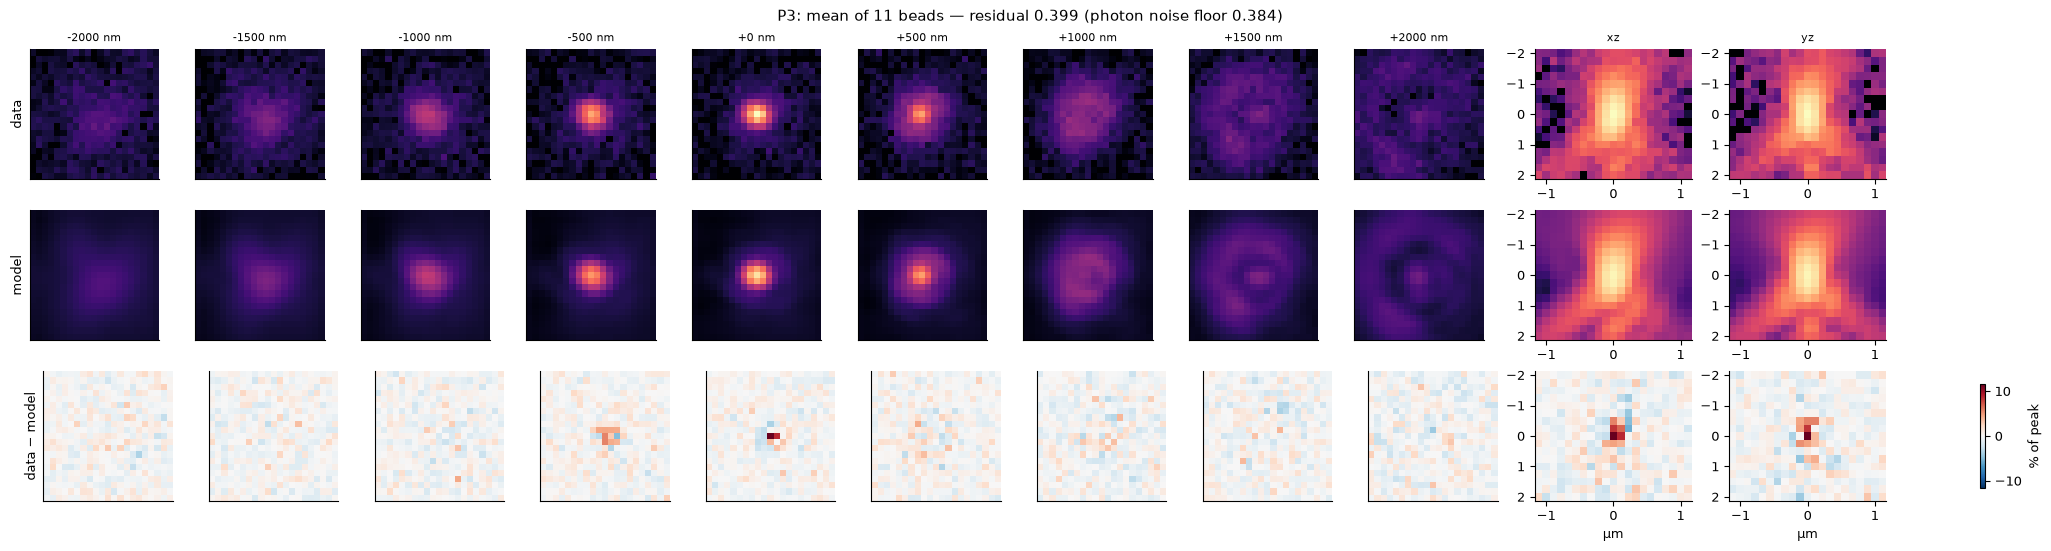

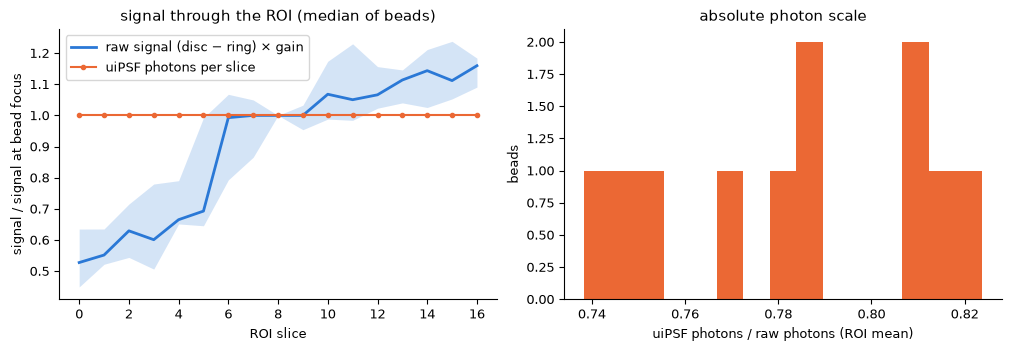

across the ROI: uiPSF photons ×1.00, raw signal ×1.94; photons fit/raw at focus 0.73  -> MISMATCH: the raw signal changes (bleaching?) while the model assumes constant photons


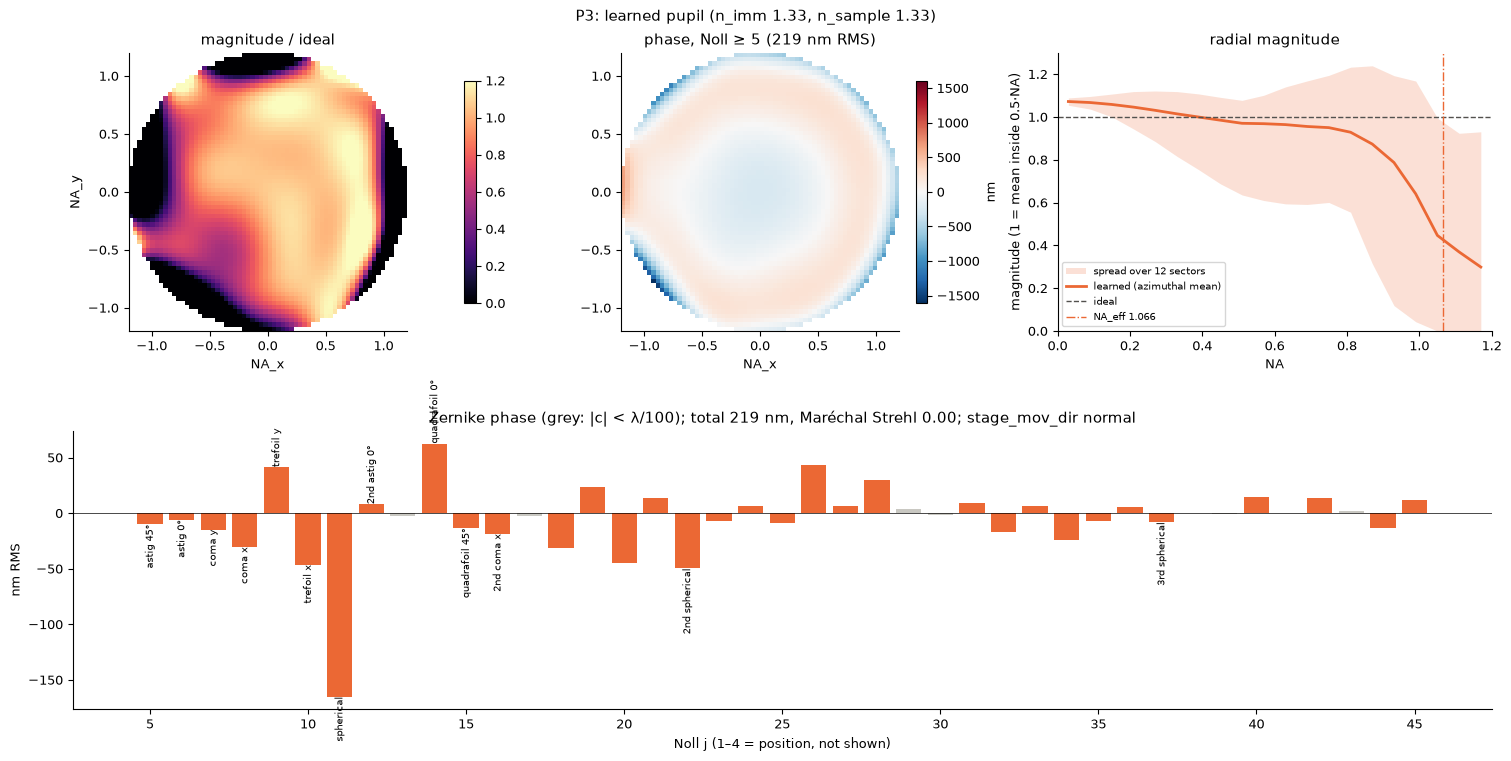

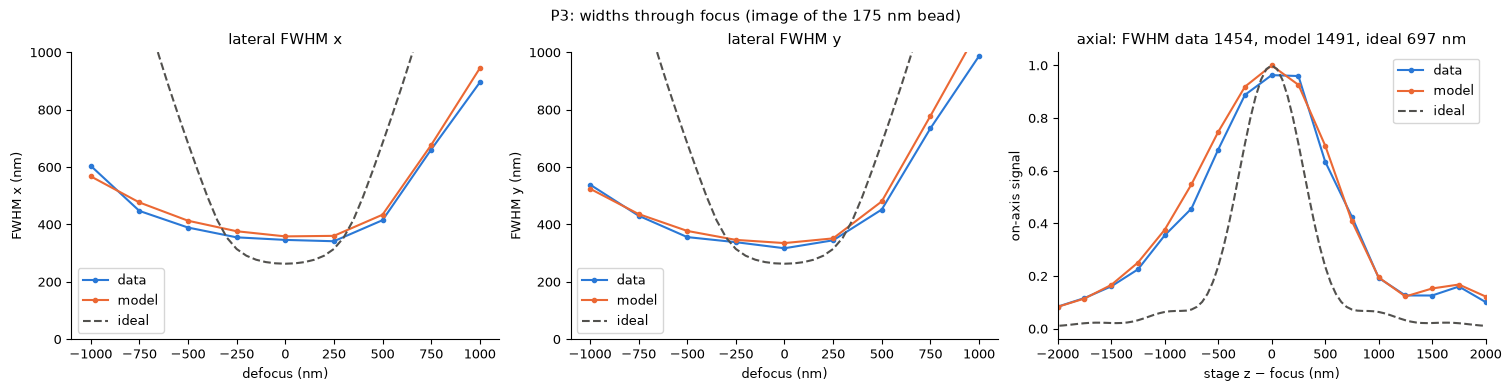

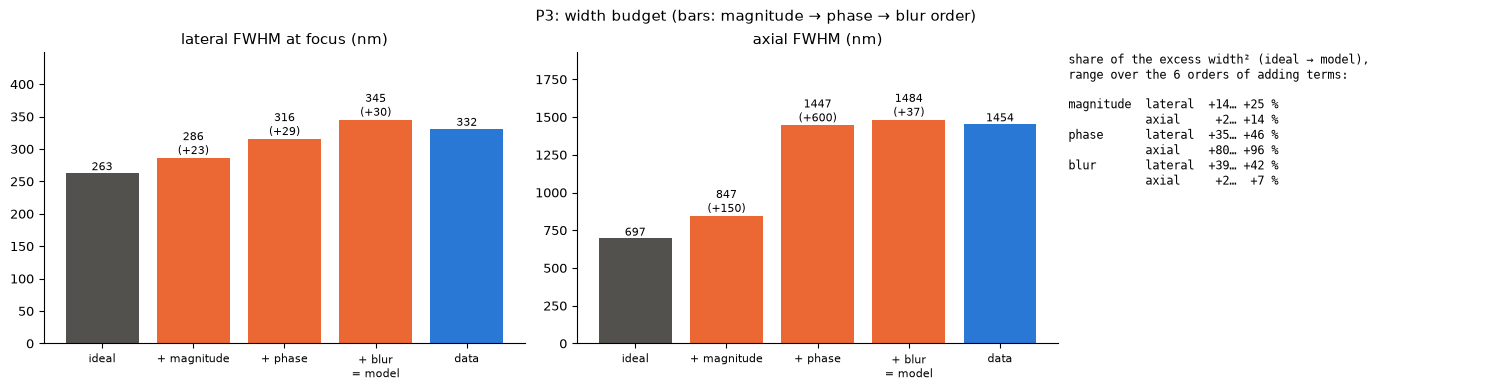

11 beads; residual 0.399 vs photon-noise floor 0.384; pupil rebuild dev 3.3e-06; forward-model port vs uiPSF 2.3e-07
NA_eff 1.066 (nominal 1.2); phase 218.9 nm RMS (Strehl 0.00); blur σ_y/σ_x 59/70 nm (pixel alone ≈ 32)
FWHM at focus x/y: data 346/317 nm, model 359/335 nm
=================== P4


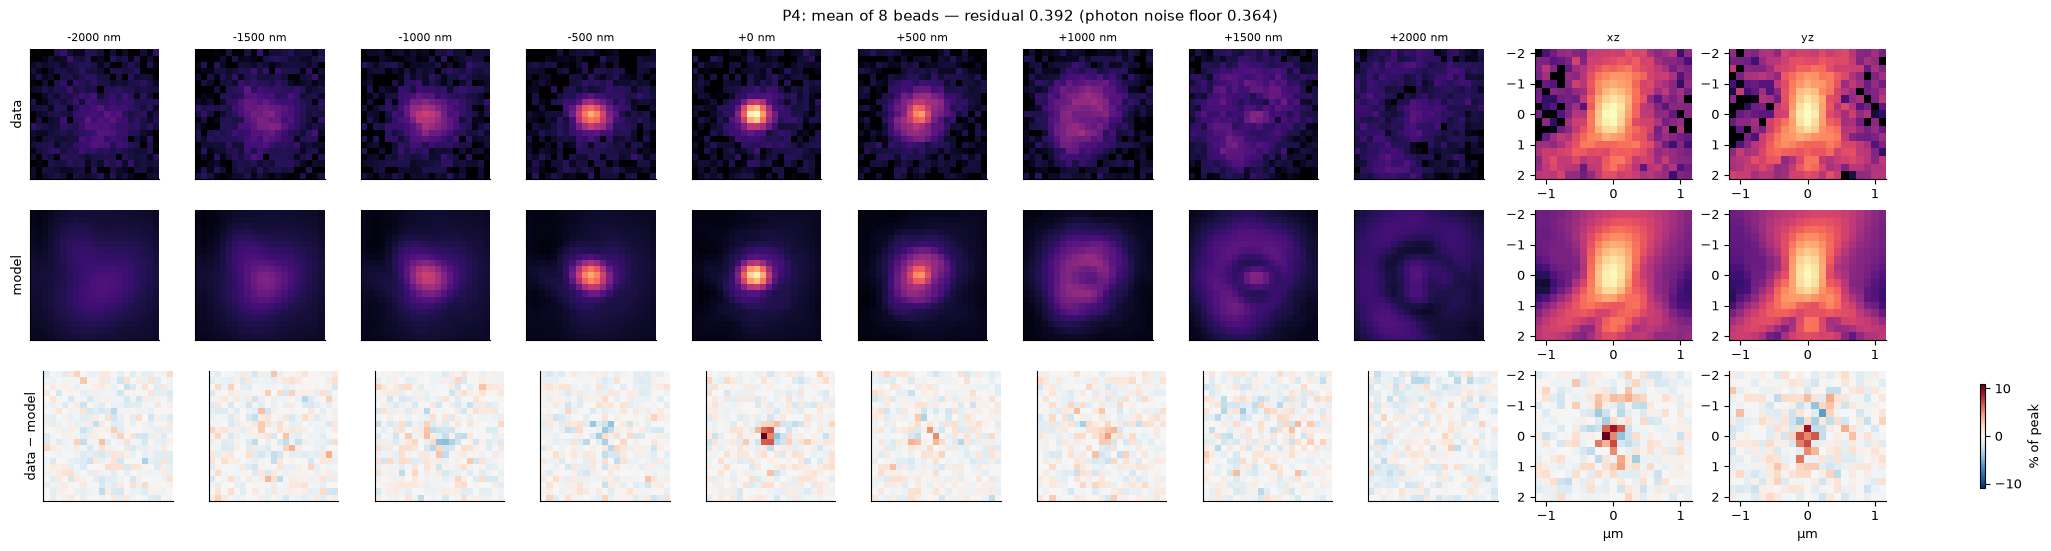

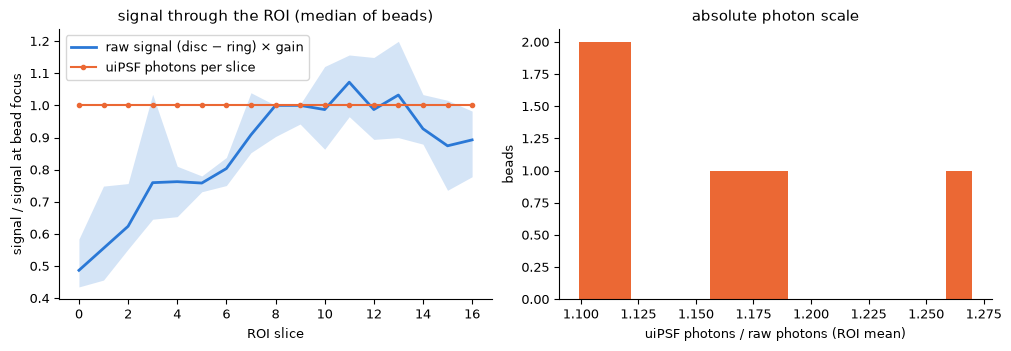

across the ROI: uiPSF photons ×1.00, raw signal ×1.66; photons fit/raw at focus 1.05  -> MISMATCH: the raw signal changes (bleaching?) while the model assumes constant photons


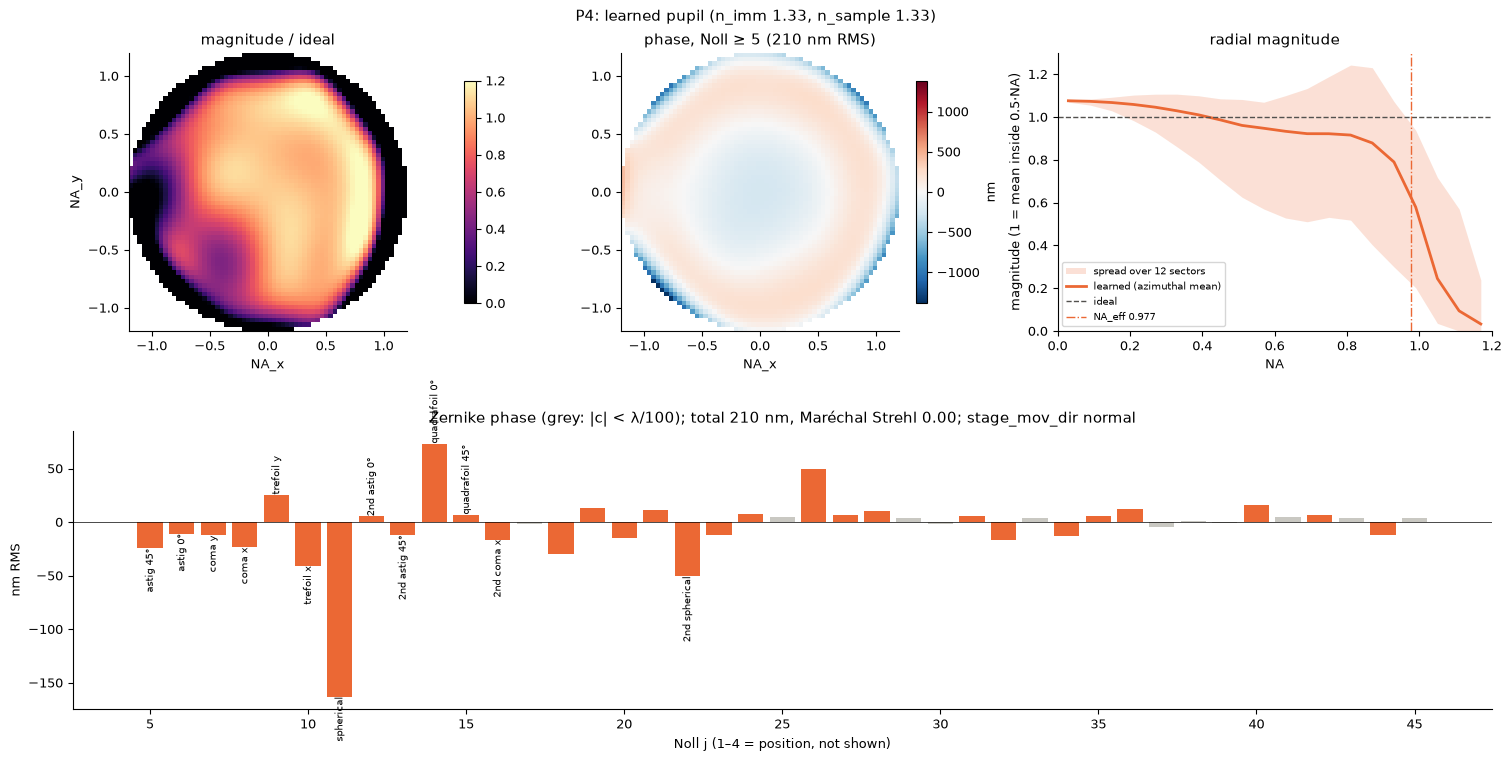

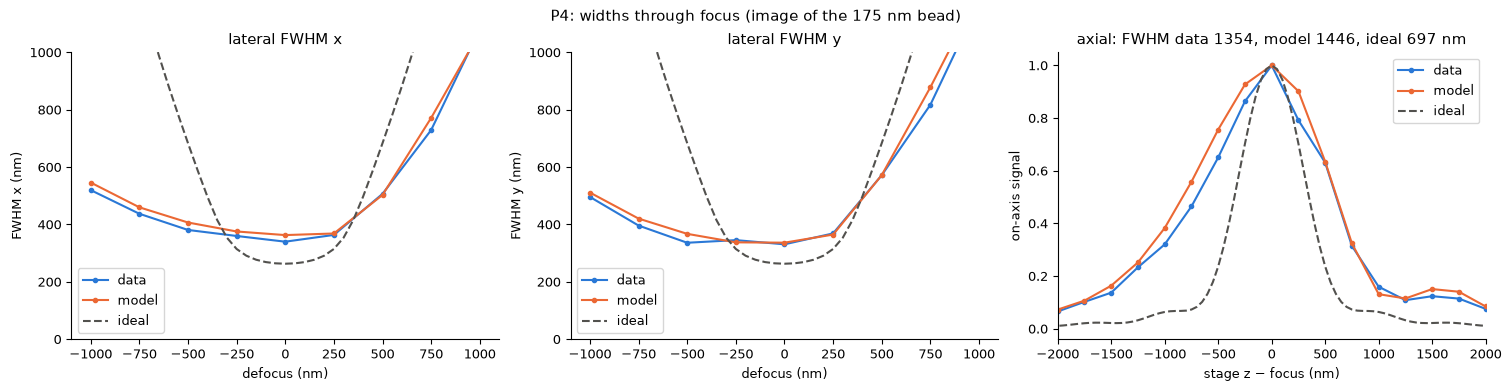

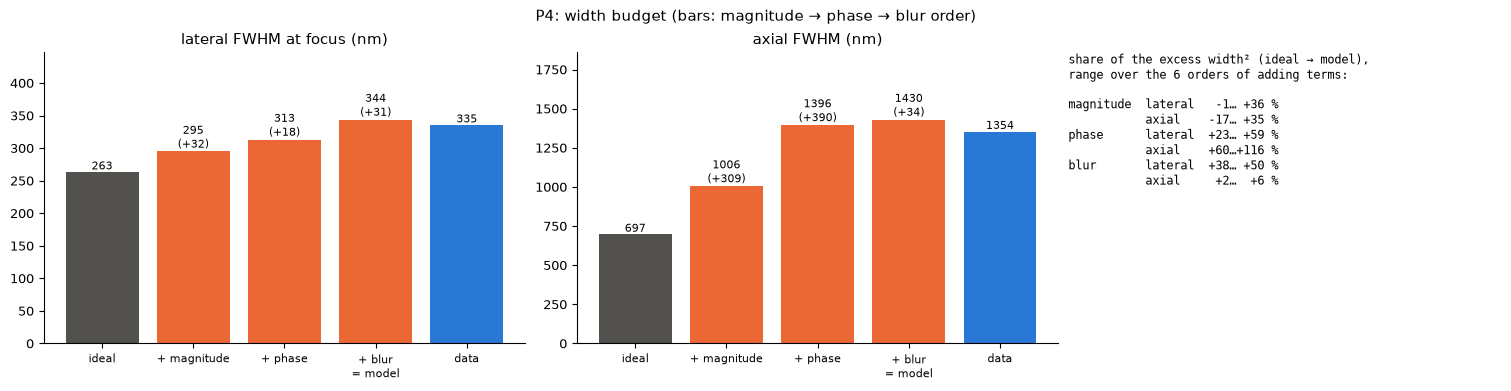

8 beads; residual 0.392 vs photon-noise floor 0.364; pupil rebuild dev 1.1e-06; forward-model port vs uiPSF 3.0e-07
NA_eff 0.977 (nominal 1.2); phase 210.0 nm RMS (Strehl 0.00); blur σ_y/σ_x 56/74 nm (pixel alone ≈ 32)
FWHM at focus x/y: data 340/331 nm, model 363/337 nm
=================== P5


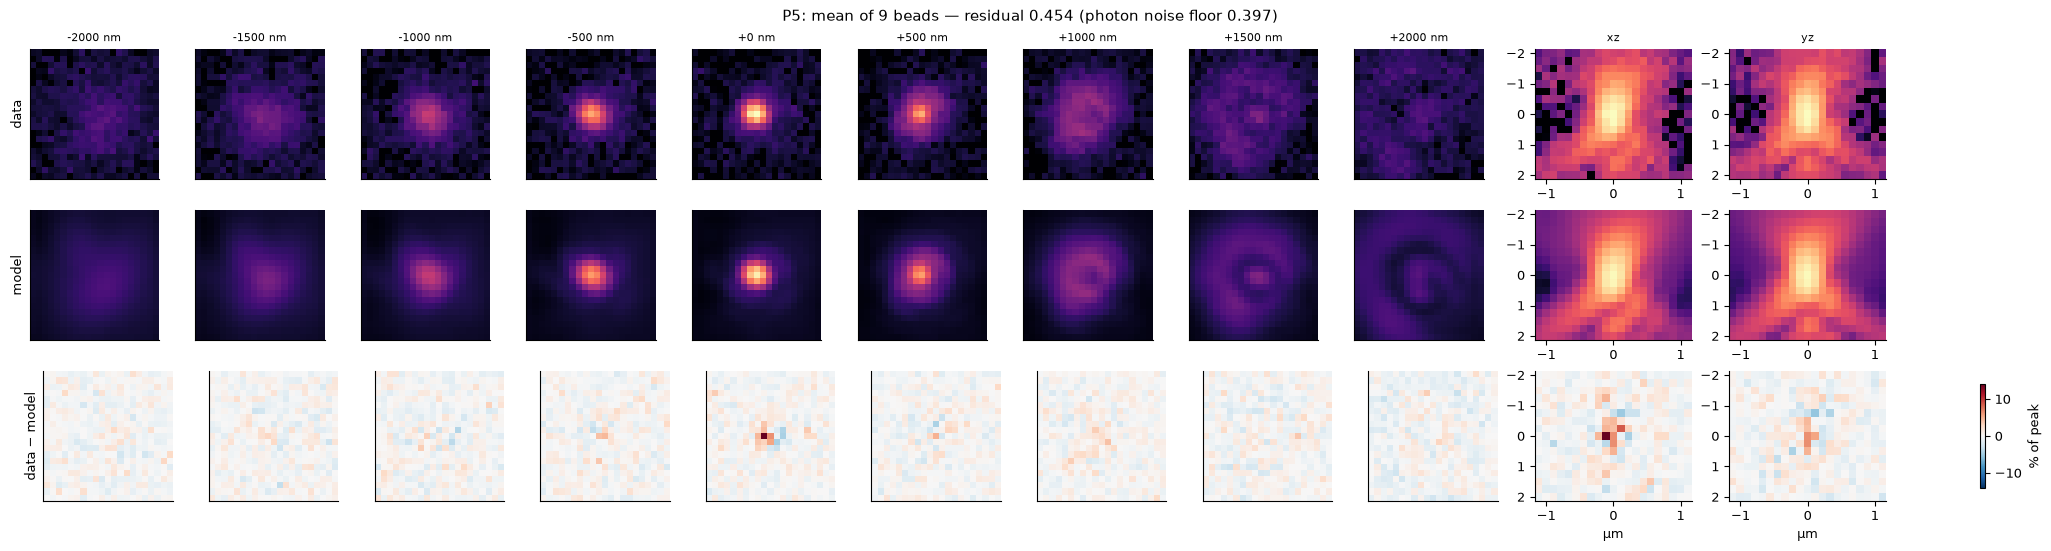

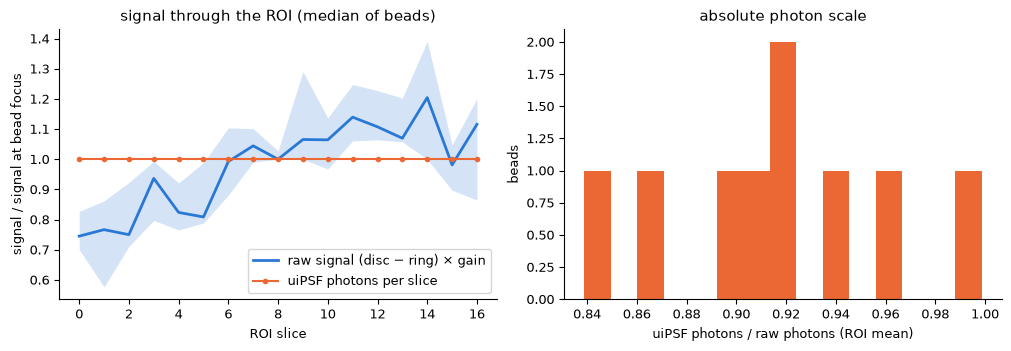

across the ROI: uiPSF photons ×1.00, raw signal ×1.48; photons fit/raw at focus 0.90


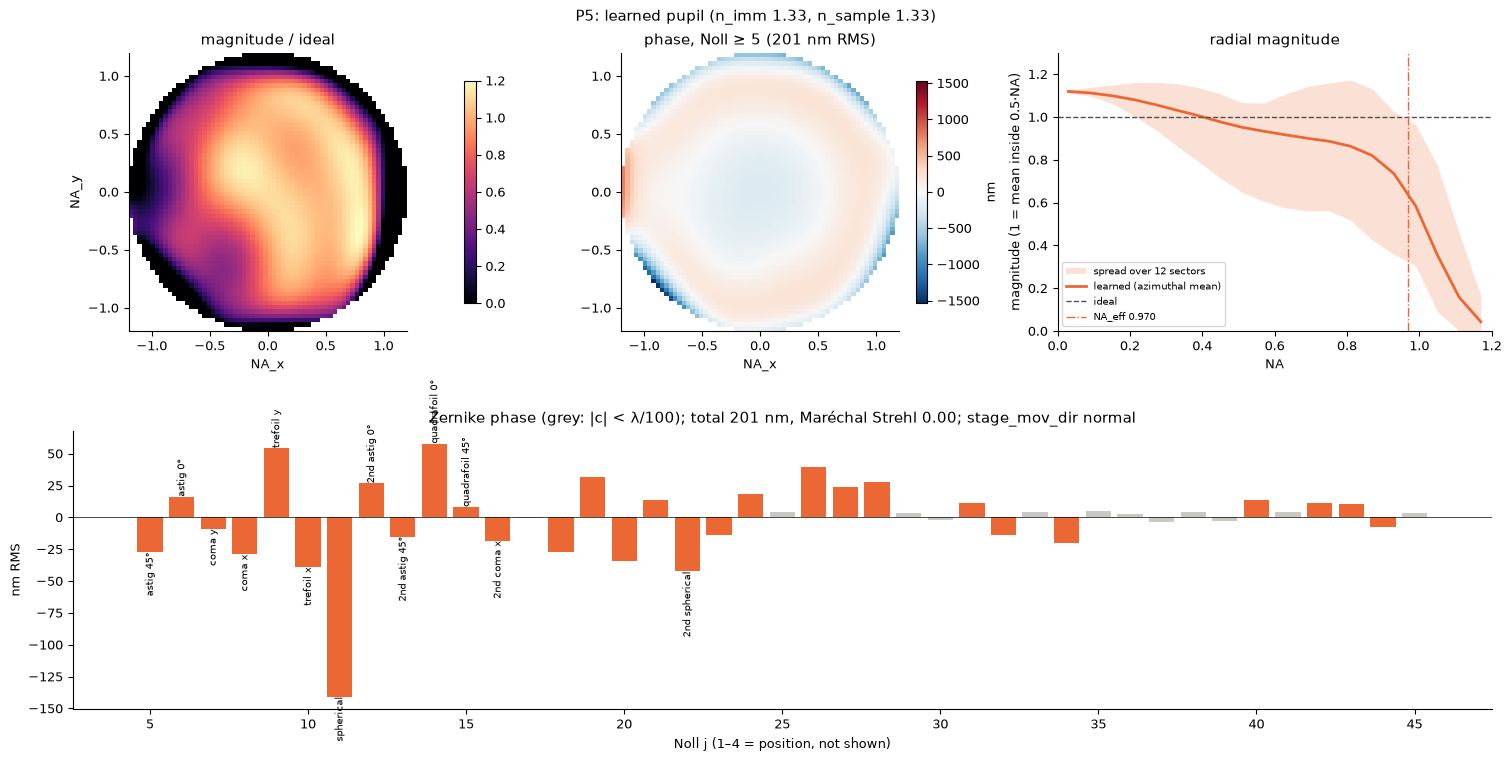

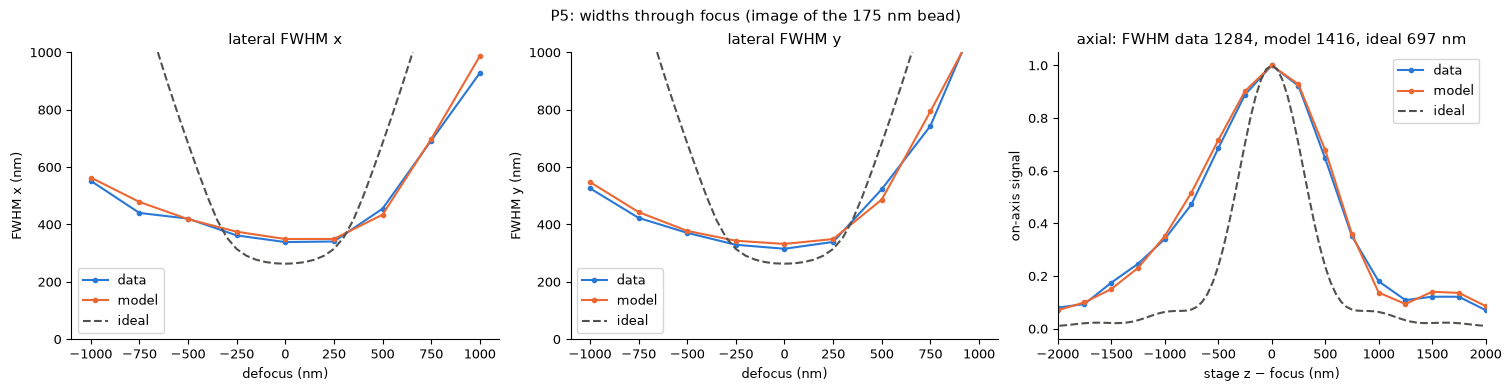

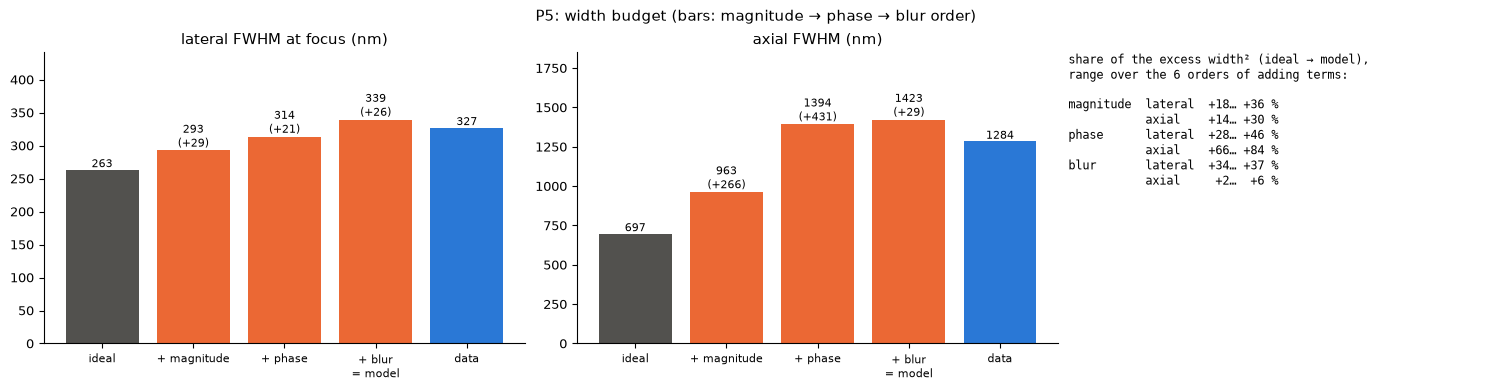

9 beads; residual 0.454 vs photon-noise floor 0.397; pupil rebuild dev 1.2e-06; forward-model port vs uiPSF 4.3e-07
NA_eff 0.970 (nominal 1.2); phase 201.5 nm RMS (Strehl 0.00); blur σ_y/σ_x 56/66 nm (pixel alone ≈ 32)
FWHM at focus x/y: data 339/315 nm, model 349/332 nm
=================== P6


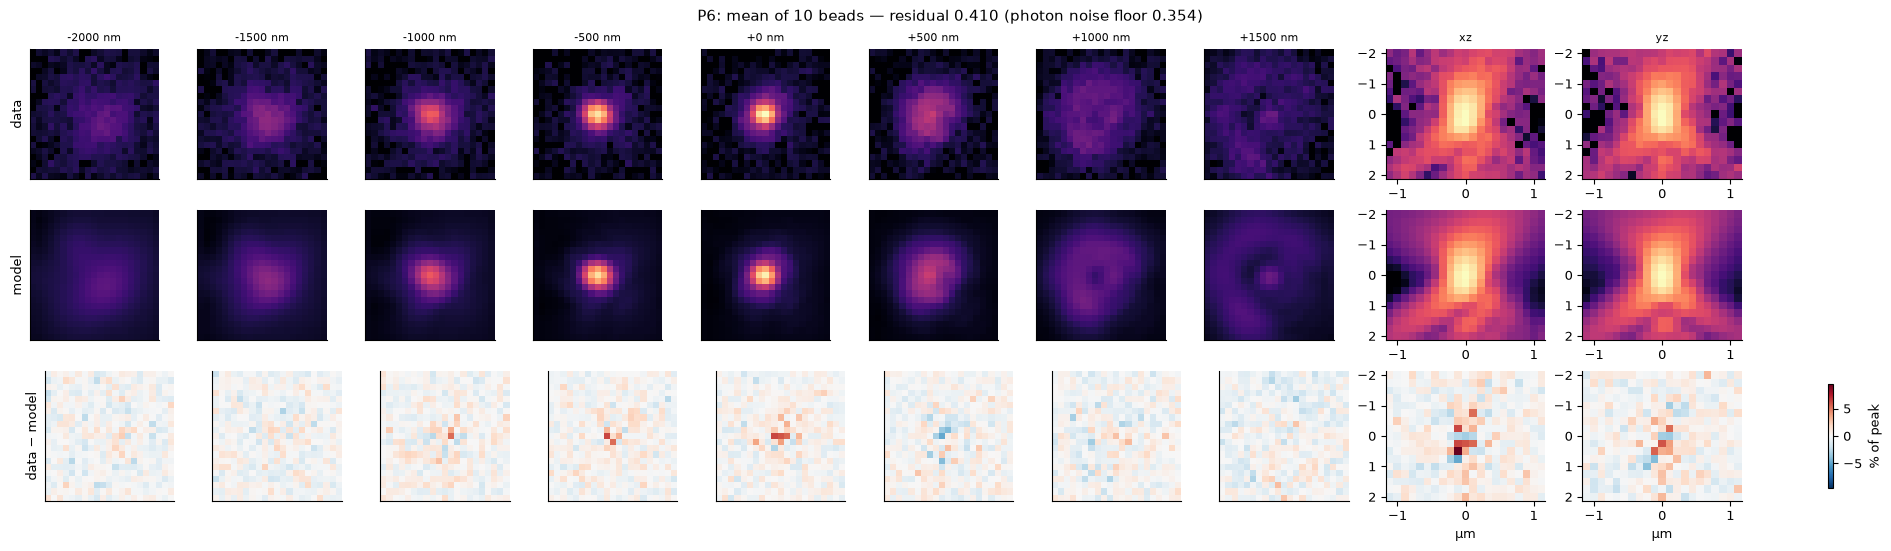

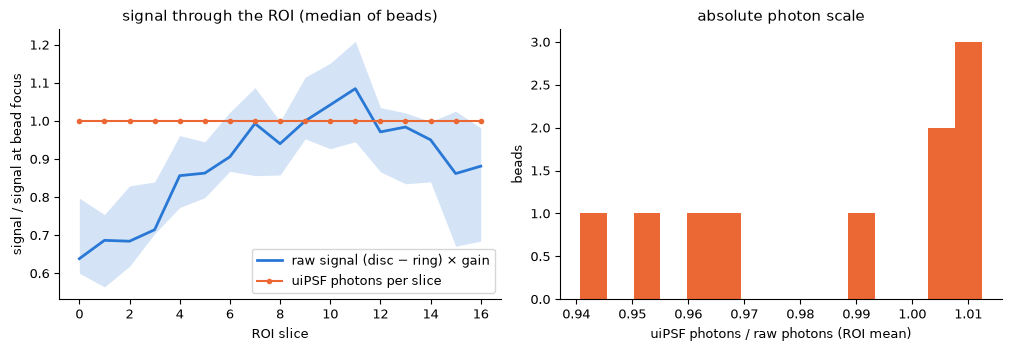

across the ROI: uiPSF photons ×1.00, raw signal ×1.31; photons fit/raw at focus 0.89


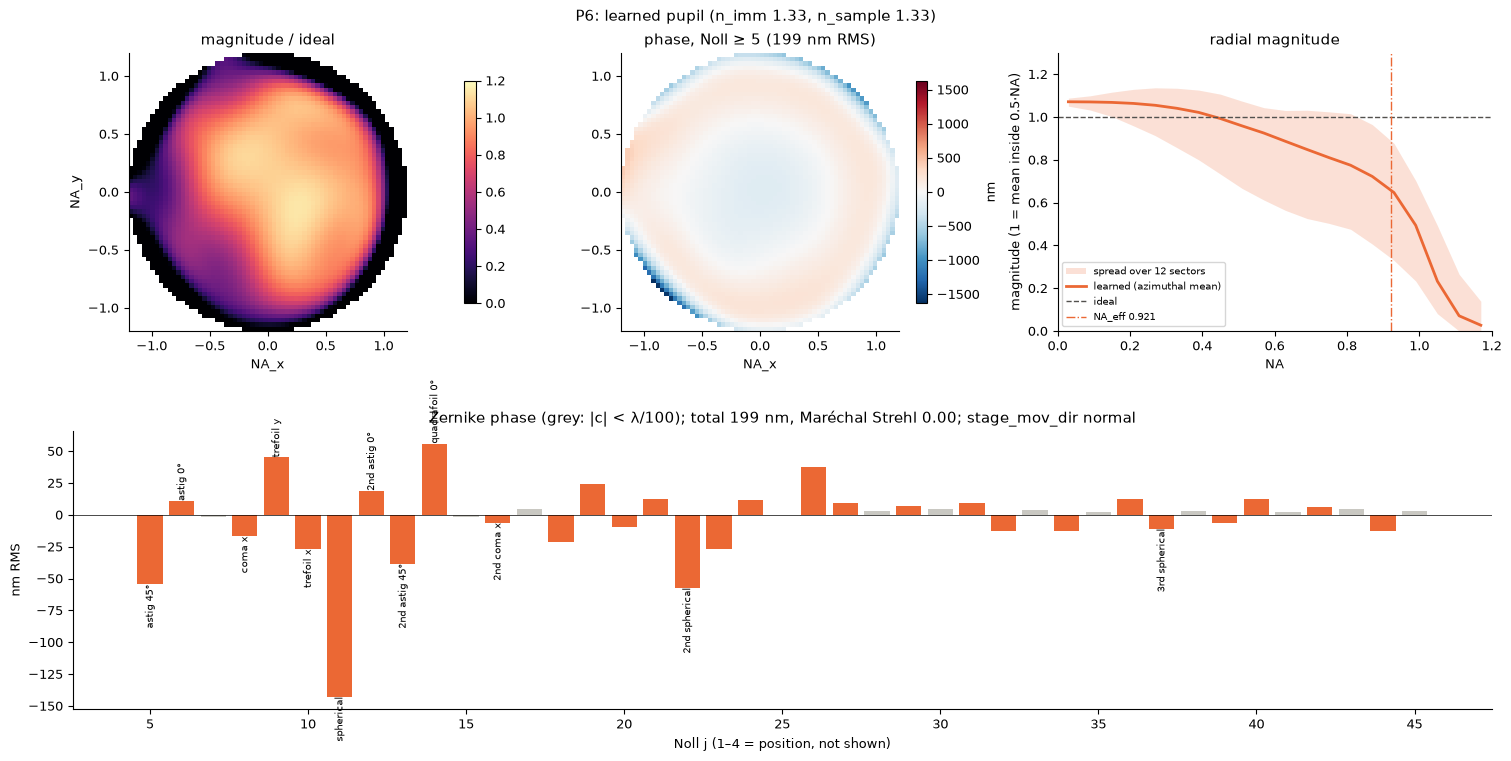

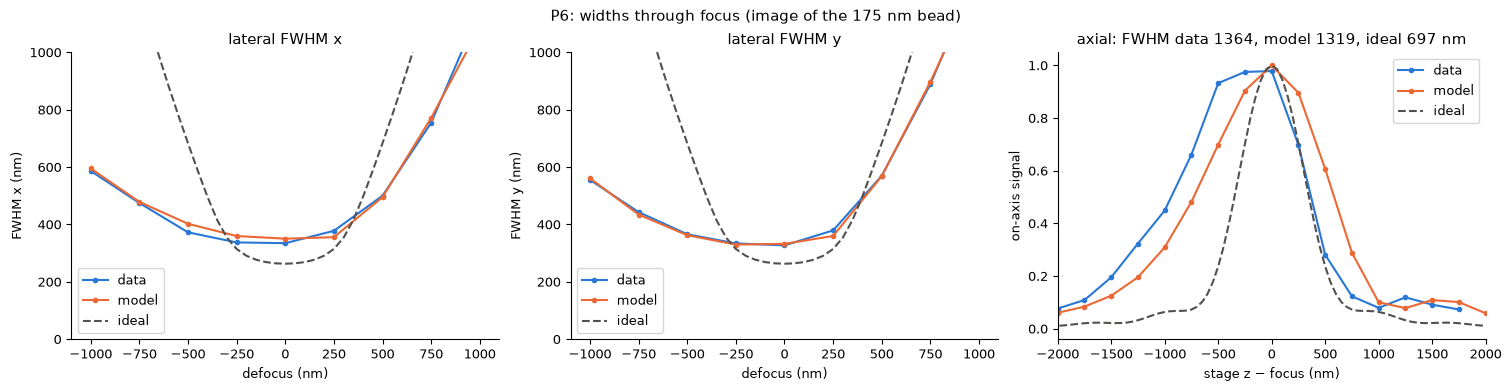

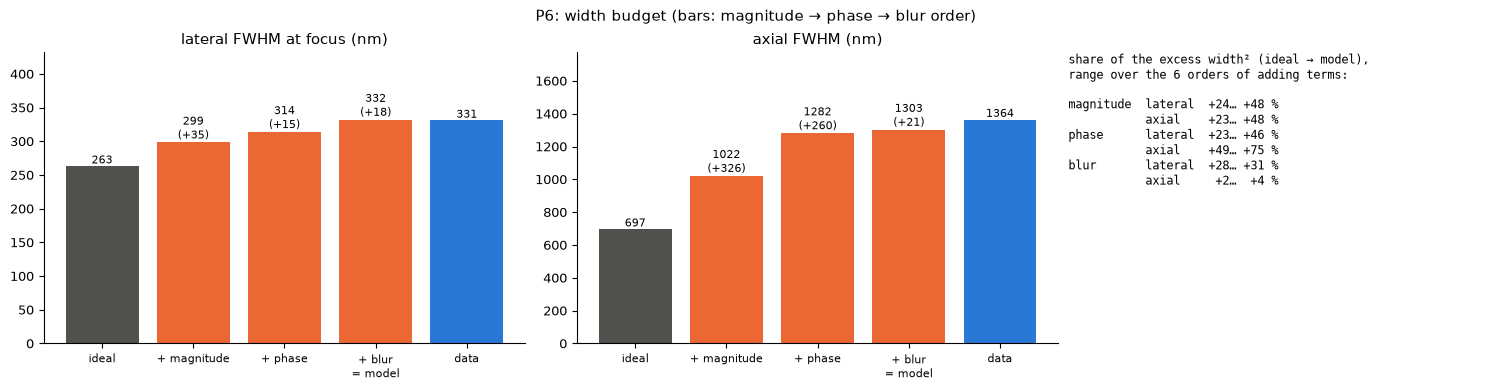

10 beads; residual 0.410 vs photon-noise floor 0.354; pupil rebuild dev 1.1e-06; forward-model port vs uiPSF 2.2e-07
NA_eff 0.921 (nominal 1.2); phase 199.0 nm RMS (Strehl 0.00); blur σ_y/σ_x 49/61 nm (pixel alone ≈ 32)
FWHM at focus x/y: data 335/327 nm, model 350/332 nm
=================== P7


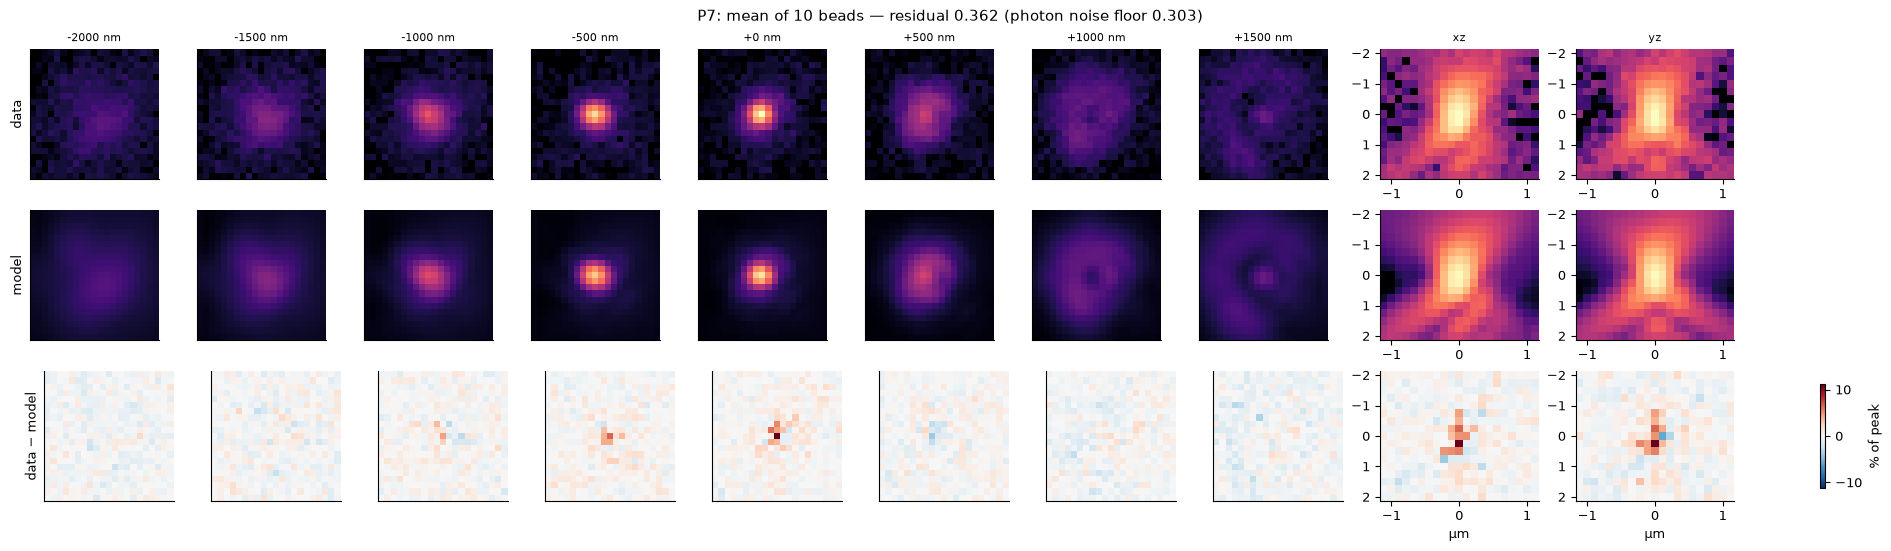

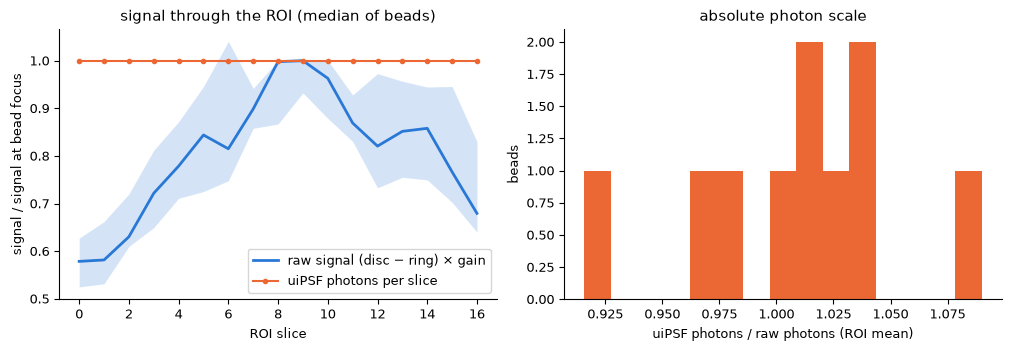

across the ROI: uiPSF photons ×1.00, raw signal ×1.30; photons fit/raw at focus 0.82


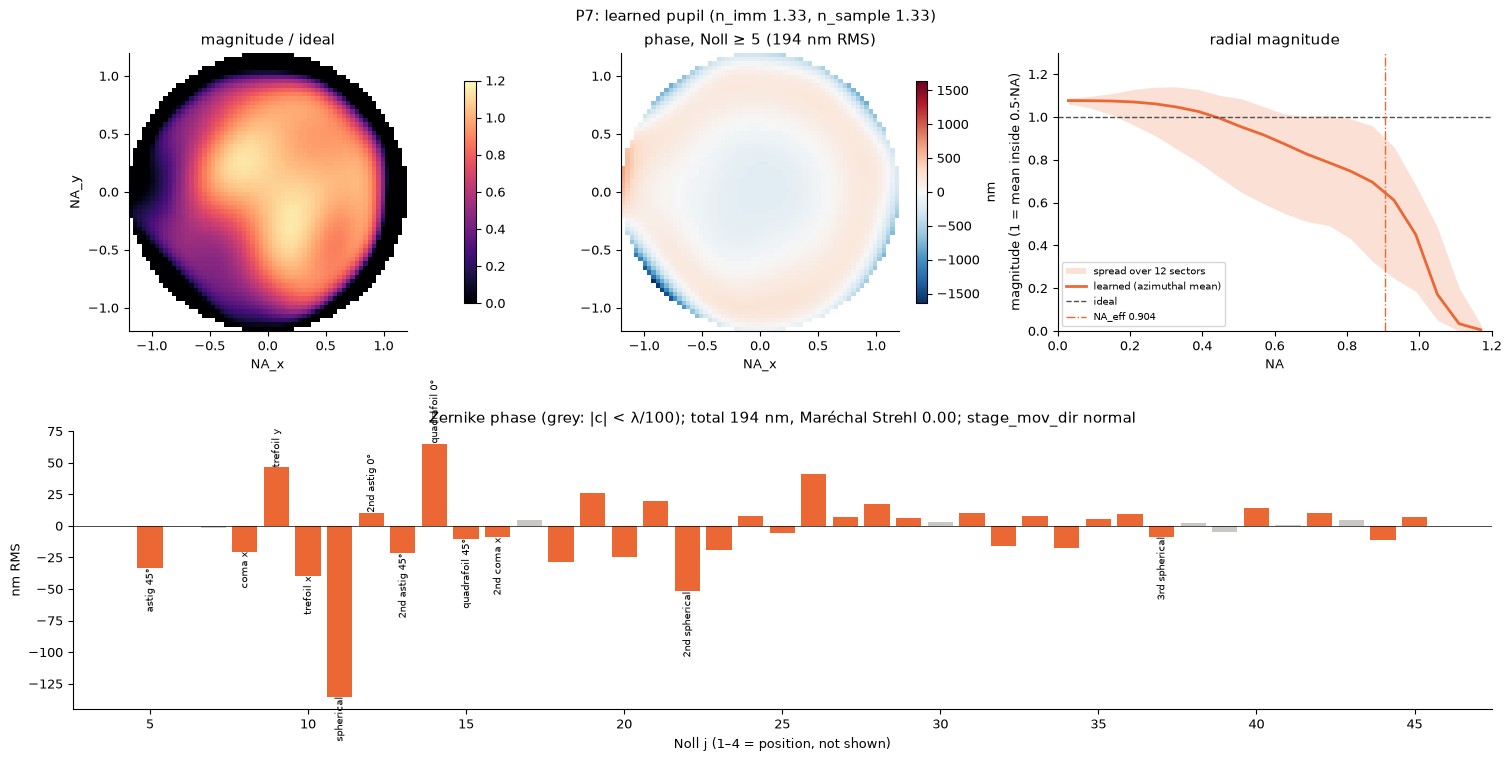

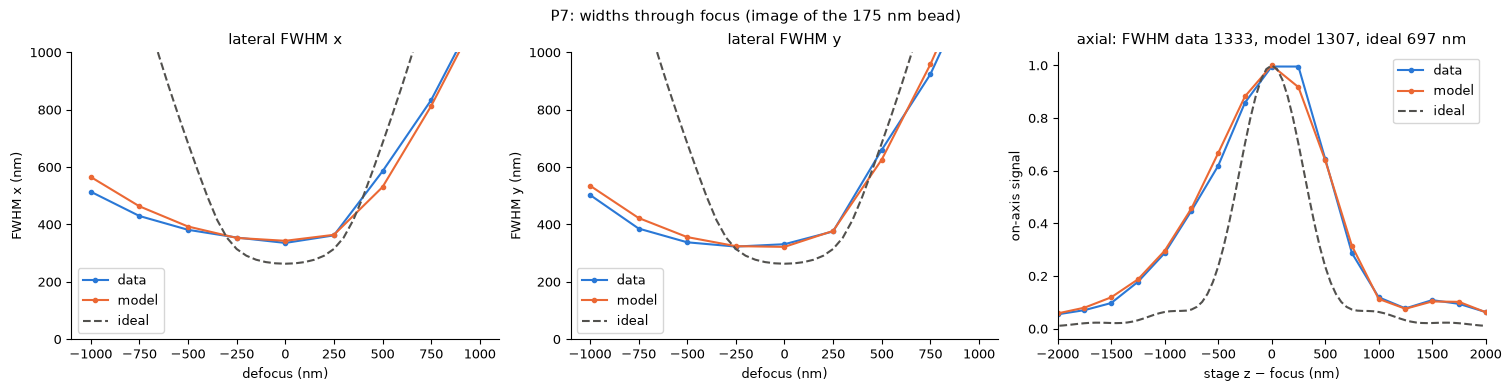

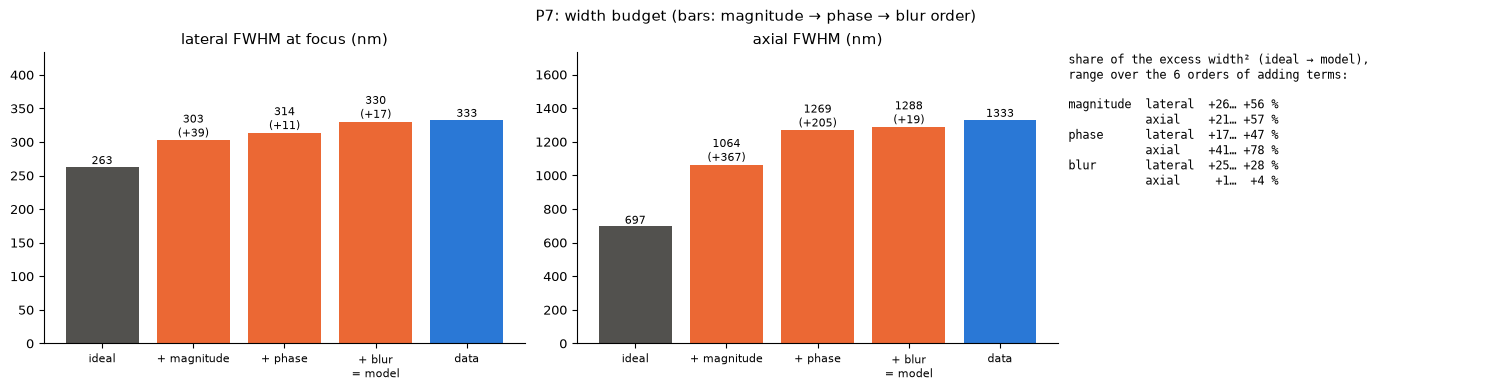

10 beads; residual 0.362 vs photon-noise floor 0.303; pupil rebuild dev 1.1e-06; forward-model port vs uiPSF 2.8e-07
NA_eff 0.904 (nominal 1.2); phase 194.3 nm RMS (Strehl 0.00); blur σ_y/σ_x 47/58 nm (pixel alone ≈ 32)
FWHM at focus x/y: data 336/331 nm, model 343/322 nm
=================== P8


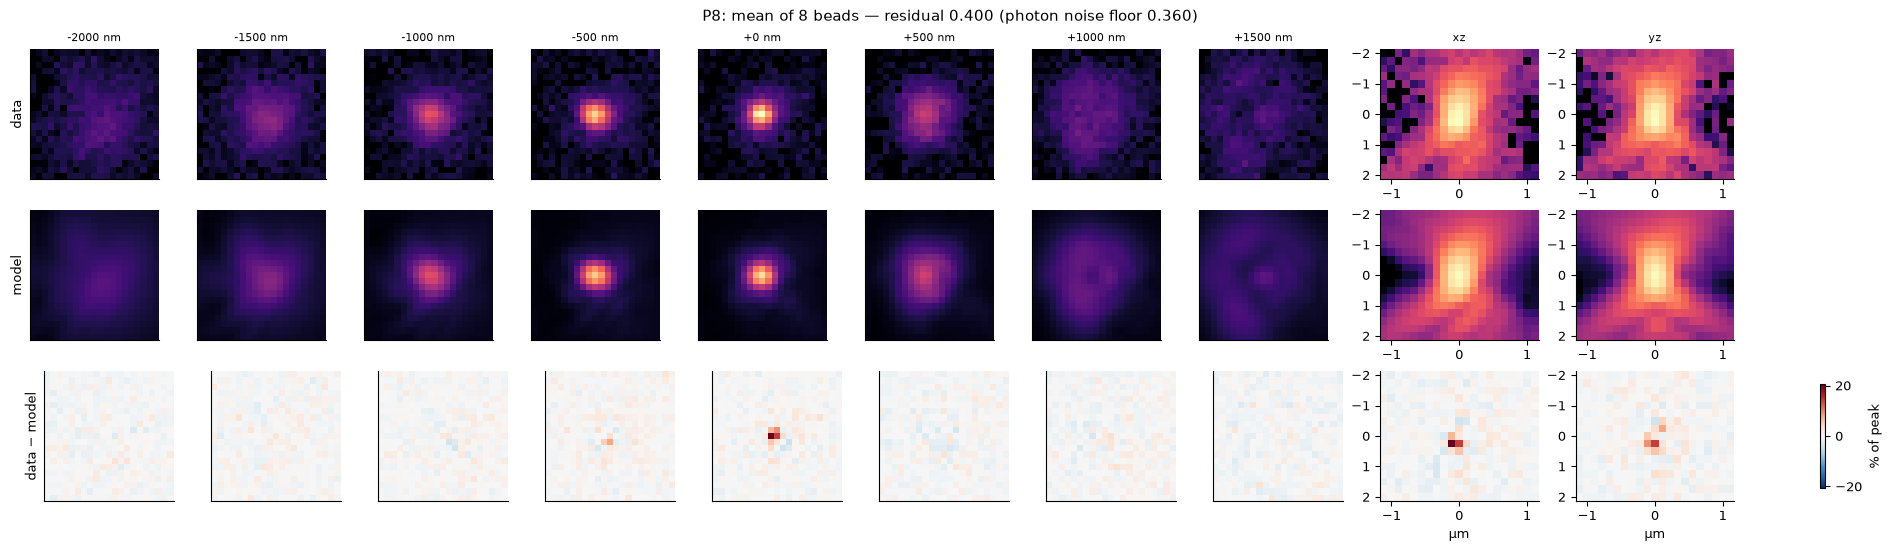

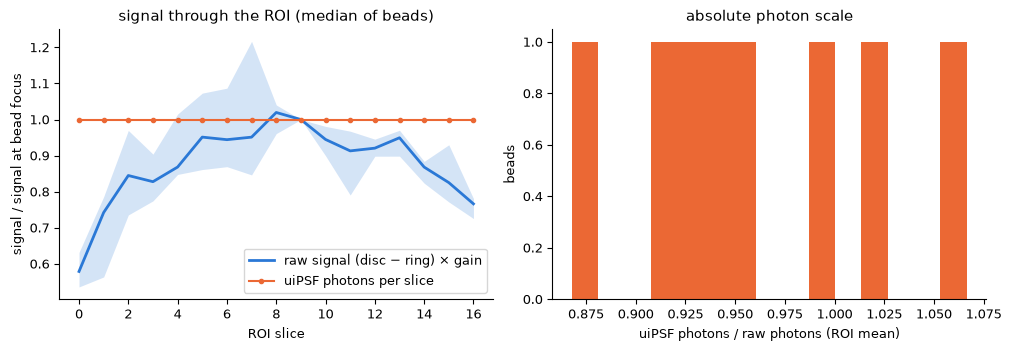

across the ROI: uiPSF photons ×1.00, raw signal ×1.20; photons fit/raw at focus 0.83


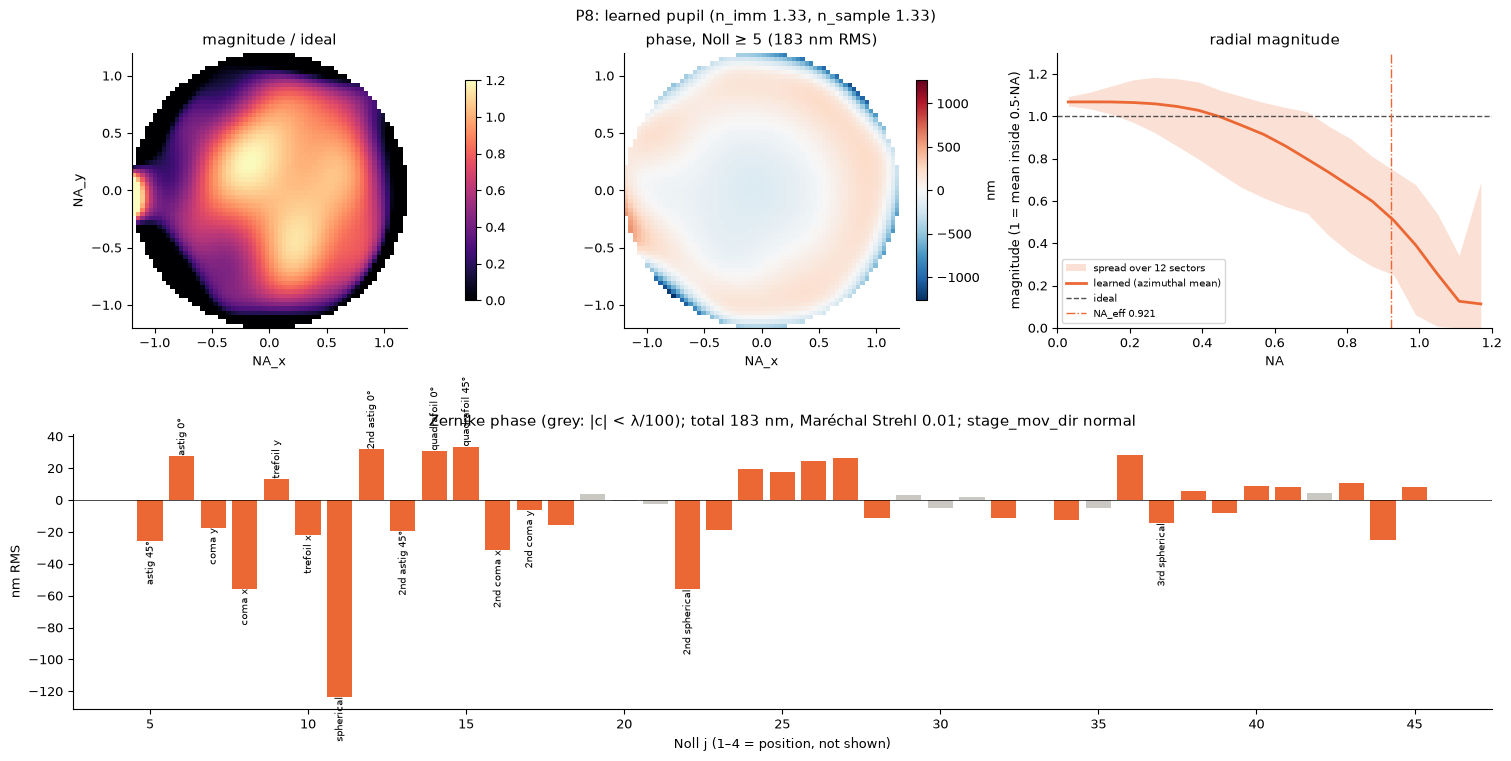

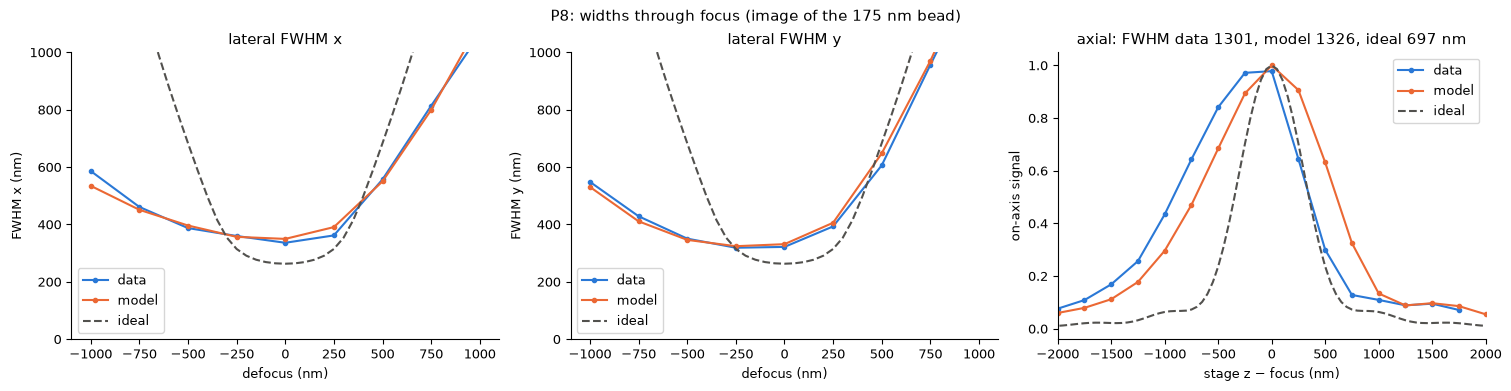

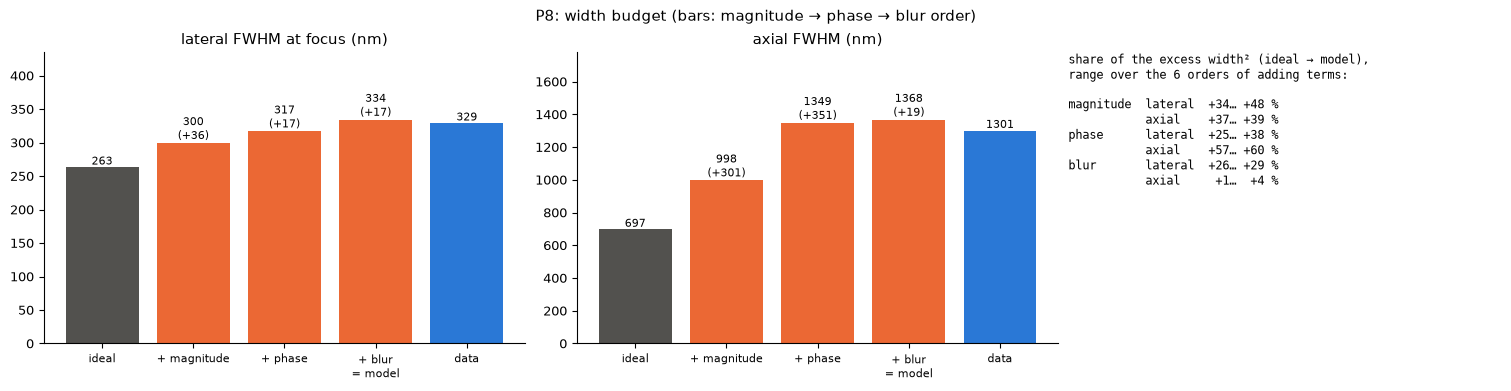

8 beads; residual 0.400 vs photon-noise floor 0.360; pupil rebuild dev 7.3e-07; forward-model port vs uiPSF 3.2e-07
NA_eff 0.921 (nominal 1.2); phase 183.1 nm RMS (Strehl 0.01); blur σ_y/σ_x 46/62 nm (pixel alone ≈ 32)
FWHM at focus x/y: data 336/322 nm, model 350/331 nm


In [7]:
zf = np.arange(-B_ZH, B_ZH + B_DZ / 2, B_DZ)
for pl, h5 in H5.items():
    print(f"=================== {pl}")
    res = pu.load_result(h5); RES[pl] = res; o = res["optics"]
    assert abs(o["n_med"] - N_SAMPLE) < 1e-9, "the fit was made with another n_sample: interpretation would be inconsistent"
    rb, floor = pu.residuals(res); D, M = pu.bead_average(res)
    fit_montage(pl, res, D, M, rb, floor, 5)
    stack = tifffile.imread(OUT / "stacks" / EXP[pl]["file"])
    chk = pu.raw_signal_check(res, stack, GAIN, DISC_UM, RING_UM)
    flag = photon_check(pl, chk, 5)
    mag, ph, dev = pu.pupil_terms(res)
    pup = pupil_figure(pl, res, mag, ph, 5)
    fm = pu.ForwardModel(o, res["zernike_polynomial"].shape[-1], res["data"].shape[-1])
    mchk = pu.model_check(res, fm)
    wt = pu.widths_through_focus(res, AX_WIN)
    bud = pu.budget(res, fm, zf, B_OVS, AX_WIN)
    widths_figure(pl, res, wt, bud, zf, 5)
    bfig = budget_figure(pl, bud, wt, res, 5)
    bl = pu.blur_sigma(res)
    print(f"{len(rb)} beads; residual {np.median(rb):.3f} vs photon-noise floor {np.median(floor):.3f}; pupil rebuild dev {dev:.1e}; "
          f"forward-model port vs uiPSF {mchk:.1e}")
    print(f"NA_eff {pup['na_eff']:.3f} (nominal {o['na']}); phase {pup['W_nm']:.1f} nm RMS (Strehl {pup['strehl_marechal']:.2f}); blur σ_y/σ_x "
          f"{bl['sigma_yx_nm'][0]:.0f}/{bl['sigma_yx_nm'][1]:.0f} nm (pixel alone ≈ {bl['pixel_alone_nm']:.0f})")
    px = 1e3 * o["px_um"]
    print(f"FWHM at focus x/y: data {px * wt['focus_data_px'][0]:.0f}/{px * wt['focus_data_px'][1]:.0f} nm, model "
          f"{px * wt['focus_model_px'][0]:.0f}/{px * wt['focus_model_px'][1]:.0f} nm")
    REP[pl] = dict(h5=str(h5), stream=EXP[pl]["stream"], delta_z_um=EXP[pl]["delta_z_um"], pixel_um=o["px_um"], beads=int(len(rb)),
                   residual_median=float(np.median(rb)), photon_noise_floor_median=float(np.median(floor)),
                   pupil_rebuild_dev=dev, forward_model_dev=mchk, blur=bl,
                   fwhm_focus_nm=dict(data_xy=(px * wt["focus_data_px"]).tolist(), model_xy=(px * wt["focus_model_px"]).tolist(),
                                      axial_data=1e3 * float(np.nanmedian(wt["axial_data_um"])), axial_model=1e3 * float(np.nanmedian(wt["axial_model_um"]))),
                   photons=None if chk is None else dict(change_fit=chk["change_fit"], change_raw=chk["change_raw"],
                                                         ratio_fit_over_raw=chk["ratio_fit_over_raw_at_focus"], mismatch_flag=flag),
                   budget=bfig, **pup)

## 6. All planes
Zernike terms per plane (Noll ≥ 5), split into the part **common** to all planes (sample, objective, tube lens — everything before
the prism) and the **plane-specific** part (prism paths, SI §6.2; cameras), the latter fitted as a linear trend with the plane's Δz +
a camera A − B offset + rest. Blur and effective NA per plane. Note: the Zernike angles are in each plane's oriented panel frame,
which matches the reference up to the small affine rotation printed in §3.

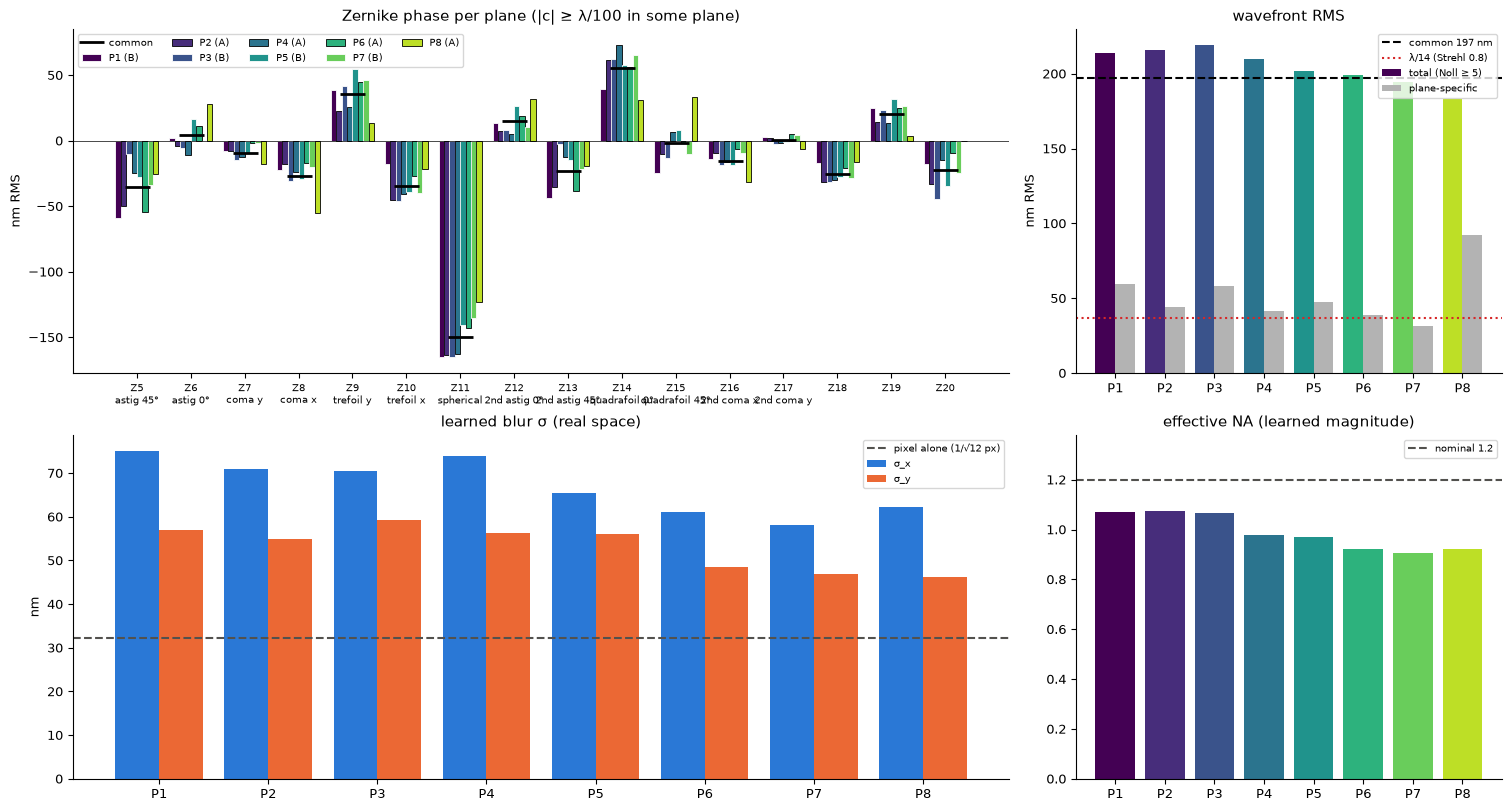

common part 197.4 nm RMS; plane-specific median 45.6 nm = depth trend ±46.5, camera A − B 40.9, rest 42.5 nm (NaN: < 4 planes or one camera)
NA_eff: P1 1.072, P2 1.073, P3 1.066, P4 0.977, P5 0.970, P6 0.921, P7 0.904, P8 0.921


In [8]:
PL = [p for p in PLANES if p in REP]
if PL:
    coef = np.array([REP[p]["phase_nm"][4:] for p in PL]); J = np.arange(5, coef.shape[1] + 5)
    split = pu.split_planes(coef, [REP[p]["delta_z_um"] for p in PL], [REP[p]["stream"] for p in PL])
    show = [j for j in J if np.abs(coef[:, j - 5]).max() >= 1e3 * LAM / 100][:16]
    cols = [plt.cm.viridis(i / max(len(PL) - 1, 1) * 0.9) for i in range(len(PL))]
    fig, ax = plt.subplots(2, 2, figsize=(15, 8), layout="constrained", gridspec_kw={"width_ratios": [2.2, 1]})
    a = ax[0, 0]; w = 0.8 / len(PL); x = np.arange(len(show))
    for i, p in enumerate(PL):
        a.bar(x - 0.4 + w * (i + 0.5), coef[i, [j - 5 for j in show]], w, color=cols[i], ec="k" if REP[p]["stream"] == "A" else "w",
              lw=0.6, label=f"{p} ({REP[p]['stream']})")
    a.plot(x, np.array(split["common_nm"])[[j - 5 for j in show]], "k_", ms=18, mew=2, label="common")
    a.set_xticks(x); a.set_xticklabels([f"Z{j}\n{pu.ZNAME.get(j, '')}" for j in show], fontsize=7)
    a.axhline(0, color="k", lw=0.5); a.set(ylabel="nm RMS", title="Zernike phase per plane (|c| ≥ λ/100 in some plane)"); a.legend(ncol=5, fontsize=7)
    a = ax[0, 1]
    a.bar(np.arange(len(PL)) - 0.2, split["W_total"], 0.4, color=cols, label="total (Noll ≥ 5)")
    a.bar(np.arange(len(PL)) + 0.2, split["W_plane_specific"], 0.4, color="0.7", label="plane-specific")
    a.axhline(split["W_common"], color="k", ls="--", label=f"common {split['W_common']:.0f} nm")
    a.axhline(1e3 * LAM / 14, color="C3", ls=":", label="λ/14 (Strehl 0.8)")
    a.set(xticks=range(len(PL)), xticklabels=PL, ylabel="nm RMS", title="wavefront RMS"); a.legend(fontsize=7)
    a = ax[1, 0]; s = np.array([REP[p]["blur"]["sigma_yx_nm"] for p in PL])
    a.bar(np.arange(len(PL)) - 0.2, s[:, 1], 0.4, color=C_D, label="σ_x"); a.bar(np.arange(len(PL)) + 0.2, s[:, 0], 0.4, color=C_M, label="σ_y")
    a.axhline(REP[PL[0]]["blur"]["pixel_alone_nm"], color=C_I, ls="--", label="pixel alone (1/√12 px)")
    a.set(xticks=range(len(PL)), xticklabels=PL, ylabel="nm", title="learned blur σ (real space)"); a.legend(fontsize=7)
    a = ax[1, 1]; ne = [REP[p]["na_eff"] for p in PL]
    a.bar(range(len(PL)), ne, color=cols); a.axhline(NA, color=C_I, ls="--", label=f"nominal {NA}")
    if N_SAMPLE < NA:
        a.axhline(N_SAMPLE, color="C3", ls=":", label=f"n_sample {N_SAMPLE}")
    a.set(xticks=range(len(PL)), xticklabels=PL, ylim=(0, 1.15 * NA), title="effective NA (learned magnitude)"); a.legend(fontsize=7)
    fig.savefig(OUT / "6_all_planes.png"); plt.show()
    print(f"common part {split['W_common']:.1f} nm RMS; plane-specific median {np.median(split['W_plane_specific']):.1f} nm = depth trend "
          f"±{split['W_depth_trend']:.1f}, camera A − B {split['W_camera']:.1f}, rest {split['W_rest']:.1f} nm (NaN: < 4 planes or one camera)")
    print("NA_eff: " + ", ".join(f"{p} {v:.3f}" for p, v in zip(PL, ne)))
else:
    split = None
    print("no fitted plane yet")

## 7. Summary
Read the NA-loss and axial numbers as model-dependent: magnitude, blur and (with `var_photon`) per-slice photons trade off; repeat a
plane with `symmetric_mag = True` or `var_photon = True` (new `fit_tag`) to see how much they move. The physical inputs (pixel, λ,
NA, gain, bead size) are nominal unless tagged otherwise above; px·NA/λ sets the pupil scale, so a pixel error looks like an NA change.

In [9]:
summary = dict(extension="uiPSF per-plane PSF characterisation — not in the paper (SI §6.3 is a Zemax design analysis)",
               uipsf_version=UIPSF_VERSION, n_sample=N_SAMPLE, stage_mov_dir=STAGE_DIR, planes=REP, comparison=split)
write_json(OUT / "psf_summary.json", summary, "02_psf_uipsf",
           dict(data=DATA, calibration=CALIB, **{f"fit_{p}": REP[p]["h5"] for p in REP}))
print("wrote", OUT / "psf_summary.json")

wrote /Users/quentingresil/Library/CloudStorage/OneDrive-epfl.ch/POSTDOC/data/260928_registration/20260928_134359_GPSBeads_Stock_1-10_Agarpse_2_488nm_zstack_02_psf/psf_summary.json
